# Late-Delivery Predictor for an E-Commerce Marketplace

**Dataset:** Olist Brazilian E-Commerce Public Dataset (Kaggle) · **Goal:** predict, at purchase time, whether an order will arrive after its estimated delivery date.

**How to run:** select the project's `.venv` kernel (top right), then **Run → Restart & Run All**. The notebook runs top to bottom (roughly 10 to 20 minutes, mostly the hyperparameter search; not timed on your machine) and writes the model files and the data files used by the Streamlit app.

| Section | Requirement |
|---|---|
| 1 | Problem framing |
| 2 | Data understanding |
| 3 | Exploratory data analysis |
| 4 | Data preprocessing |
| 5 | Machine learning modeling |
| 6 | Tuning and validation |
| 7 | Model evaluation on the untouched test set |
| 8 | Business insights |
| 9 | Files exported for the Streamlit application |

## 1. Problem framing

**Business problem.** A marketplace promises every customer an estimated delivery date. When an order arrives after that date, the customer is disappointed, support tickets rise and repeat purchases suffer. Today the marketplace learns about a late delivery only after it has happened.

**Who faces it.** Operations and customer-service teams (who must react), sellers (whose handling time drives delays) and customers (who receive the order late).

**Decision the model supports.** Which orders deserve proactive attention *right after purchase*, for example contacting the customer early, pushing the seller to ship faster, choosing a faster carrier or resetting the promised date. The model ranks orders by risk so the limited attention of the operations team goes to the orders most likely to be late.

**Target variable.**
- `is_late = 1` if the customer received the order on a calendar day **after** the estimated delivery date.
- `is_late = 0` if the order arrived on or before it.
- Only orders with status *delivered* and both dates present can be labelled. Canceled, unavailable and in-transit orders have no outcome yet and are excluded.

**Evaluation metrics and why they matter.**

| Metric | Why it matters here |
|---|---|
| PR-AUC (average precision) | Main metric. Late orders are rare, and PR-AUC measures how well the model ranks them above on-time orders. |
| Recall in the riskiest 10% of orders | Business reading: "if we act on 10% of orders, what share of all late deliveries do we catch?" |
| Precision / false alarms per catch | Every false alarm costs operations time. |
| F1-score | Balances precision and recall at a chosen cut-off. |
| ROC-AUC | Overall ranking quality, less informative with rare positives. |
| Accuracy | **Not used as a decision metric.** A model that always says "on time" would already score about 93%. |

**Leakage rule.** Only information available **at purchase time** may be a model input. Anything that happens after purchase (approval time, carrier hand-over, delivery date, order status, reviews) is used only to build the target and for analysis.

In [1]:
import sys
import json
import time
import platform
import warnings
from importlib.metadata import version
from pathlib import Path

# Find the project root (the folder that contains `src`), wherever the notebook is opened from
ROOT = Path.cwd().resolve()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.isotonic import IsotonicRegression
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    ConfusionMatrixDisplay, average_precision_score, brier_score_loss,
    classification_report, f1_score, precision_recall_curve, precision_score,
    recall_score, roc_auc_score, roc_curve,
)

from src.config import DATA_PROCESSED, FIGURES_DIR, MODEL_PATH, MODELS_DIR, RANDOM_STATE
from src.data_loader import load_all
from src.build_dataset import (
    ANALYSIS_ONLY, BASE_PATH, FEATURE_COLUMNS, ID_COLUMNS, NUMERIC_FEATURES, TARGET,
    build_order_table, load_base_table,
)
from src.preprocessing import (
    MODEL_FEATURES, NUMERIC_MODEL, TEST_START, build_preprocessor, split_xy,
    time_based_split,
)
from src.models import MODEL_NAMES, build_pipeline
from src.validation import FOLD_CUTOFFS, evaluate_scores, make_time_folds, top_k_metrics
from src.tuning import SCORING, SEARCH_SPACES, TUNED_MODELS, base_pipeline

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
BLUE = "#4C72B0"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

Project root: C:\Users\Ghalwash\Documents\late-delivery-predictor


## 2. Data understanding

The Olist dataset has nine CSV files. Each table is loaded with its date columns parsed as datetimes. The tables are linked like this:

```
orders ──customer_id──> customers ──zip prefix──> geolocation
  │ order_id
  ├── items ──product_id──> products ──category──> category_translation
  │          └─ seller_id──> sellers ──zip prefix──> geolocation
  ├── payments   (one or more rows per order)
  └── reviews    (written after delivery)
```

In [2]:
tables = load_all()

overview = pd.DataFrame([{
    "table": name,
    "rows": len(d),
    "columns": d.shape[1],
    "memory_MB": round(d.memory_usage(deep=True).sum() / 1_048_576, 1),
    "duplicate_rows": int(d.duplicated().sum()),
} for name, d in tables.items()])
display(overview)

,table,rows,columns,memory_MB,duplicate_rows
0,orders,99441,8,26.9,0
1,items,112650,7,32.1,0
2,customers,99441,5,29.6,0
3,sellers,3095,4,0.7,0
4,products,32951,9,6.8,0
5,payments,103886,5,17.8,0
6,reviews,99224,7,29.9,0
7,geolocation,1000163,5,145.2,261831
8,category_translation,71,2,0.0,0


**Columns, data types and missing values.** Only columns that actually contain missing values are listed.

In [3]:
for name in ["orders", "items", "customers", "sellers", "products"]:
    print(f"--- {name}: {len(tables[name]):,} rows ---")
    display(pd.DataFrame({"dtype": tables[name].dtypes.astype(str),
                          "missing": tables[name].isna().sum(),
                          "unique": tables[name].nunique()}))

miss = []
for name, d in tables.items():
    for col in d.columns:
        k = int(d[col].isna().sum())
        if k:
            miss.append({"table": name, "column": col, "dtype": str(d[col].dtype),
                         "missing": k, "missing_pct": round(k / len(d) * 100, 2)})
print("Columns with missing values (all tables):")
display(pd.DataFrame(miss))

--- orders: 99,441 rows ---


,dtype,missing,unique
order_id,object,0,99441
customer_id,object,0,99441
order_status,object,0,8
order_purchase_timestamp,datetime64[ns],0,98875
order_approved_at,datetime64[ns],160,90733
order_delivered_carrier_date,datetime64[ns],1783,81018
order_delivered_customer_date,datetime64[ns],2965,95664
order_estimated_delivery_date,datetime64[ns],0,459


--- items: 112,650 rows ---


,dtype,missing,unique
order_id,object,0,98666
order_item_id,int64,0,21
product_id,object,0,32951
seller_id,object,0,3095
shipping_limit_date,datetime64[ns],0,93318
price,float64,0,5968
freight_value,float64,0,6999


--- customers: 99,441 rows ---


,dtype,missing,unique
customer_id,object,0,99441
customer_unique_id,object,0,96096
customer_zip_code_prefix,int64,0,14994
customer_city,object,0,4119
customer_state,object,0,27


... (2 outputs left out)

--- products: 32,951 rows ---


,dtype,missing,unique
product_id,object,0,32951
product_category_name,object,610,73
product_name_lenght,float64,610,66
product_description_lenght,float64,610,2960
product_photos_qty,float64,610,19
product_weight_g,float64,2,2204
product_length_cm,float64,2,99
product_height_cm,float64,2,102
product_width_cm,float64,2,95


Columns with missing values (all tables):


,table,column,dtype,missing,missing_pct
0,orders,order_approved_at,datetime64[ns],160,0.16
1,orders,order_delivered_carrier_date,datetime64[ns],1783,1.79
2,orders,order_delivered_customer_date,datetime64[ns],2965,2.98
3,products,product_category_name,object,610,1.85
4,products,product_name_lenght,float64,610,1.85
5,products,product_description_lenght,float64,610,1.85
6,products,product_photos_qty,float64,610,1.85
7,products,product_weight_g,float64,2,0.01
8,products,product_length_cm,float64,2,0.01
9,products,product_height_cm,float64,2,0.01


**Do the join keys really match?** Every relationship in the diagram is measured instead of assumed.

In [4]:
links = [
    ("orders", "customer_id", "customers", "customer_id"),
    ("items", "order_id", "orders", "order_id"),
    ("payments", "order_id", "orders", "order_id"),
    ("reviews", "order_id", "orders", "order_id"),
    ("items", "product_id", "products", "product_id"),
    ("items", "seller_id", "sellers", "seller_id"),
    ("products", "product_category_name", "category_translation", "product_category_name"),
    ("customers", "customer_zip_code_prefix", "geolocation", "geolocation_zip_code_prefix"),
    ("sellers", "seller_zip_code_prefix", "geolocation", "geolocation_zip_code_prefix"),
]
rel = pd.DataFrame([{
    "child key": f"{c}.{cc}",
    "parent key": f"{p}.{pc}",
    "matched_%": round(tables[c][cc].dropna().isin(tables[p][pc]).mean() * 100, 2),
    "parent key unique": tables[p][pc].is_unique,
} for c, cc, p, pc in links])
display(rel)

orders, items = tables["orders"], tables["items"]
per_order = items.groupby("order_id").agg(n_items=("order_item_id", "size"),
                                          n_sellers=("seller_id", "nunique"))
print(f"Orders without item rows: {int((~orders['order_id'].isin(items['order_id'])).sum()):,}")
print(f"Orders with more than one seller: {int((per_order['n_sellers'] > 1).sum()):,}")
print(f"Max items in one order: {per_order['n_items'].max()}")
print(f"Geolocation duplicate rows: {int(tables['geolocation'].duplicated().sum()):,} "
      "(the zip code key is not unique, so it must be collapsed before joining)")

,child key,parent key,matched_%,parent key unique
0,orders.customer_id,customers.customer_id,100.00,True
1,items.order_id,orders.order_id,100.00,True
2,payments.order_id,orders.order_id,100.00,True
3,reviews.order_id,orders.order_id,100.00,True
4,items.product_id,products.product_id,100.00,True
5,items.seller_id,sellers.seller_id,100.00,True
6,products.product_category_name,category_translation.product_category_name,99.96,True
7,customers.customer_zip_code_prefix,geolocation.geolocation_zip_code_prefix,99.72,False
8,sellers.seller_zip_code_prefix,geolocation.geolocation_zip_code_prefix,99.77,False


Orders without item rows: 775
Orders with more than one seller: 1,278
Max items in one order: 21
Geolocation duplicate rows: 261,831 (the zip code key is not unique, so it must be collapsed before joining)


**Order status, date range and class balance.** The target needs a delivered order with both a delivery date and an estimated date. The estimated date has no time of day, so "late" is judged on calendar days.

In [5]:
status = orders["order_status"].value_counts().to_frame("orders")
status["pct"] = (status["orders"] / len(orders) * 100).round(2)
display(status)
print("Purchase dates:", orders["order_purchase_timestamp"].min(), "->",
      orders["order_purchase_timestamp"].max())

delivered = orders[orders["order_status"] == "delivered"].dropna(
    subset=["order_delivered_customer_date", "order_estimated_delivery_date"])
d_day = delivered["order_delivered_customer_date"].dt.normalize()
e_day = delivered["order_estimated_delivery_date"].dt.normalize()
late_day = d_day > e_day
late_exact = delivered["order_delivered_customer_date"] > delivered["order_estimated_delivery_date"]
print(f"\nLabelled orders: {len(delivered):,}")
print(f"Late, calendar-day comparison (chosen): {late_day.sum():,} ({late_day.mean() * 100:.2f}%)")
print(f"Late, exact timestamp comparison:       {late_exact.sum():,} ({late_exact.mean() * 100:.2f}%)")

,orders,pct
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


Purchase dates: 2016-09-04 21:15:19 -> 2018-10-17 17:30:18

Labelled orders: 96,470
Late, calendar-day comparison (chosen): 6,534 (6.77%)
Late, exact timestamp comparison:       7,826 (8.11%)


**Build one row per order.** Items, products, sellers, payments and the collapsed geolocation table are aggregated into a single order-level table (`src/build_dataset.py`). Every column is placed in one of three groups:

- `TARGET`: what we predict.
- `FEATURE_COLUMNS`: known at purchase time, allowed as model inputs.
- `ANALYSIS_ONLY`: known only after purchase, used for analysis and error analysis, **never as a feature**.

In [6]:
df = build_order_table()
df.to_csv(BASE_PATH, index=False)
df = load_base_table()          # reload so dates are parsed exactly as the other modules expect

counts = df[TARGET].value_counts().sort_index()
print(f"\nRows: {len(df):,}   Columns: {df.shape[1]}   order_id unique: {df['order_id'].is_unique}")
print(f"On-time (0): {counts[0]:,}   Late (1): {counts[1]:,}   Late rate: {df[TARGET].mean() * 100:.2f}%")

m = df[FEATURE_COLUMNS].isna().sum()
print("\nMissing values in purchase-time features:")
display(m[m > 0].to_frame("missing"))

print("Allowed model features:", FEATURE_COLUMNS)
print("Analysis-only (never features):", ANALYSIS_ONLY)
print("Overlap:", set(FEATURE_COLUMNS) & set(ANALYSIS_ONLY) or "none")

Labelled delivered orders: 96,470
Labelled orders with no item rows (dropped): 0

Rows: 96,470   Columns: 37   order_id unique: True
On-time (0): 89,936   Late (1): 6,534   Late rate: 6.77%

Missing values in purchase-time features:


,missing
distance_km,478
total_weight_g,16
total_volume_cm3,16
max_installments,1
n_payments,1
payment_type,1


Allowed model features: ['estimated_delivery_days', 'distance_km', 'n_items', 'n_products', 'n_sellers', 'total_price', 'total_freight', 'freight_ratio', 'total_weight_g', 'total_volume_cm3', 'max_installments', 'n_payments', 'shipping_limit_days', 'purchase_month', 'purchase_dayofweek', 'purchase_hour', 'same_state', 'customer_state', 'seller_state', 'product_category', 'payment_type']
Analysis-only (never features): ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'actual_delivery_days', 'days_vs_estimate', 'review_score', 'purchase_year_month', 'customer_city', 'customer_zip_code_prefix', 'seller_zip_code_prefix']
Overlap: none


## 3. Exploratory data analysis

The whole labelled table is used here **only for reading** patterns. Nothing is fitted on it. Every statistic that drives a modelling decision is recomputed on the training split in section 4.

In [7]:
OVERALL = df[TARGET].mean() * 100


def late_rate(data, col, min_orders=1):
    g = data.groupby(col, observed=True)[TARGET].agg(orders="size", late_rate_pct="mean")
    g["late_rate_pct"] = (g["late_rate_pct"] * 100).round(2)
    return g[g["orders"] >= min_orders]


def finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / name, dpi=130)
    plt.show()


def barh_rate(tab, title, name, top=None):
    t = tab.sort_values("late_rate_pct", ascending=False)
    if top:
        t = t.head(top)
    fig, ax = plt.subplots(figsize=(9, max(3.5, 0.32 * len(t) + 1.5)))
    sns.barplot(x=t["late_rate_pct"], y=t.index.astype(str), color=BLUE, ax=ax, orient="h")
    ax.axvline(OVERALL, color="red", ls="--", label=f"overall {OVERALL:.1f}%")
    ax.set_xlabel("Late rate (%)")
    ax.set_title(title)
    ax.legend()
    finish(fig, name)


def bar_rate(tab, title, name):
    t = tab.sort_index()
    fig, ax = plt.subplots(figsize=(10, 4.5))
    sns.barplot(x=t.index.astype(str), y=t["late_rate_pct"], color=BLUE, ax=ax)
    ax.axhline(OVERALL, color="red", ls="--", label=f"overall {OVERALL:.1f}%")
    ax.set_ylabel("Late rate (%)")
    ax.set_title(title)
    ax.legend()
    plt.setp(ax.get_xticklabels(), rotation=60, ha="right")
    finish(fig, name)

### 3.1 Univariate analysis

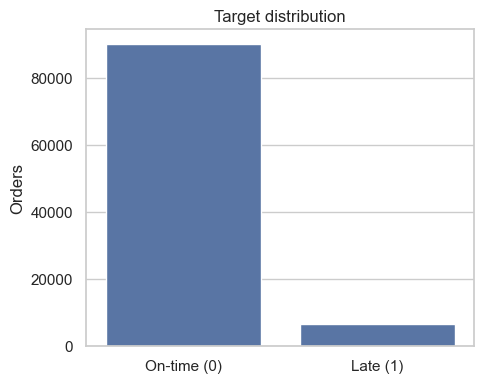

,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
estimated_delivery_days,96470.0,24.37,8.76,3.00,7.00,19.00,24.00,29.00,39.00,51.00,156.00
distance_km,95992.0,600.68,594.16,0.00,5.74,184.97,433.81,798.22,2095.70,2483.25,8677.86
total_price,96470.0,137.04,209.05,0.85,11.99,45.90,86.50,149.90,399.00,990.00,13440.00
total_freight,96470.0,22.79,21.56,0.00,7.39,13.85,17.17,24.02,54.78,104.25,1794.96
freight_ratio,96470.0,0.31,0.31,0.00,0.03,0.13,0.22,0.38,0.84,1.46,21.45
total_weight_g,96454.0,2386.87,4770.11,0.00,100.00,300.00,750.00,2050.00,10500.00,22350.00,184400.00
total_volume_cm3,96454.0,17331.94,30143.87,168.00,352.00,2964.00,7254.00,19866.00,64000.00,135690.82,1476000.00
shipping_limit_days,96470.0,6.66,4.69,2.00,2.00,5.00,6.00,7.00,12.00,19.00,1052.00


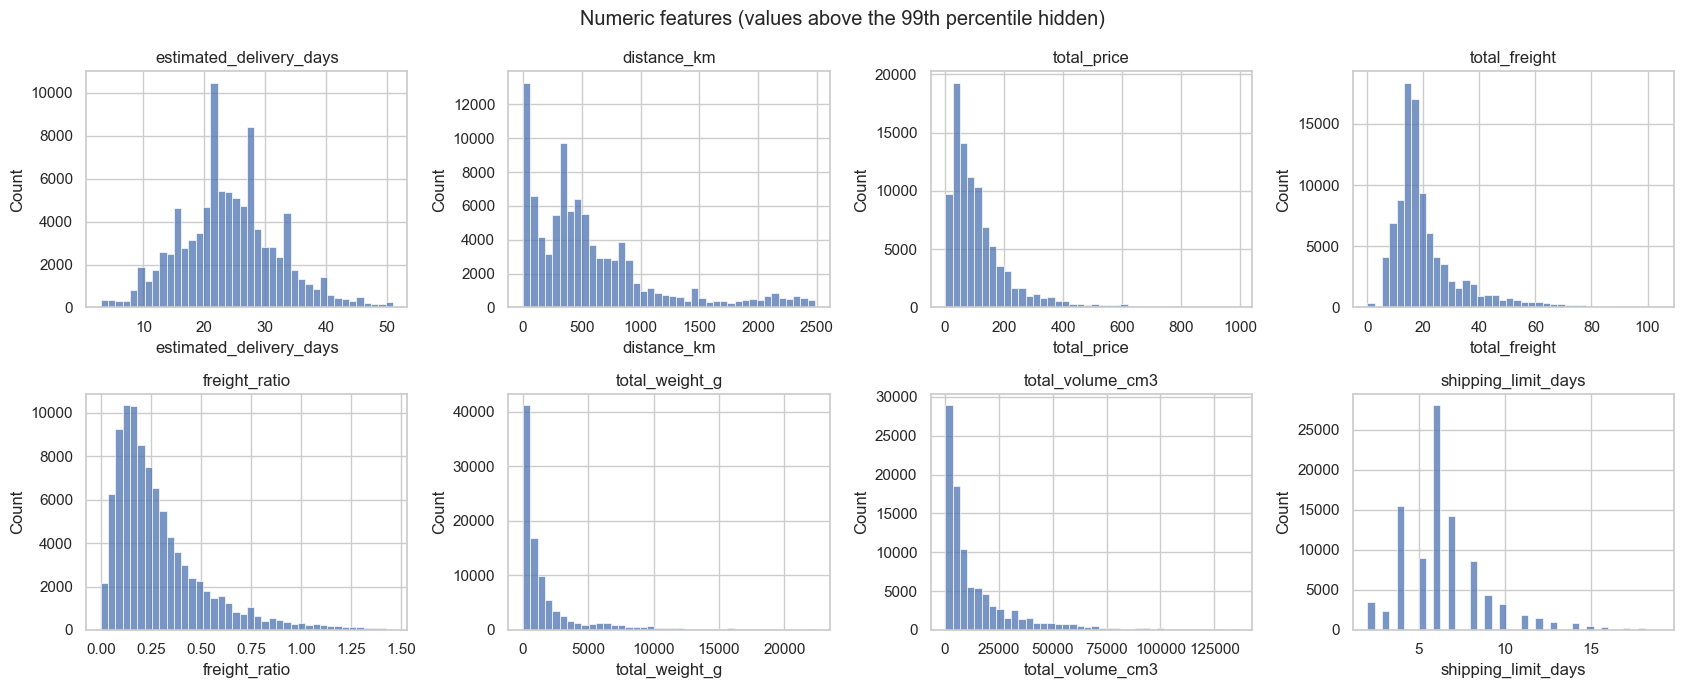

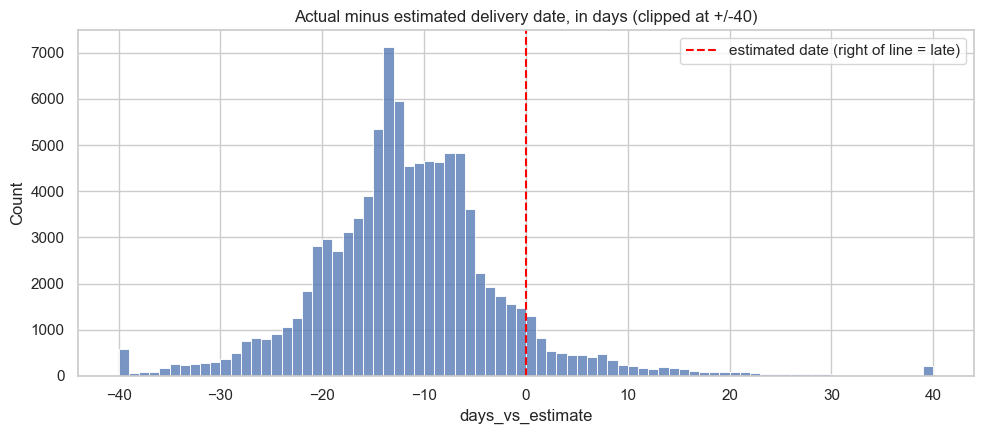

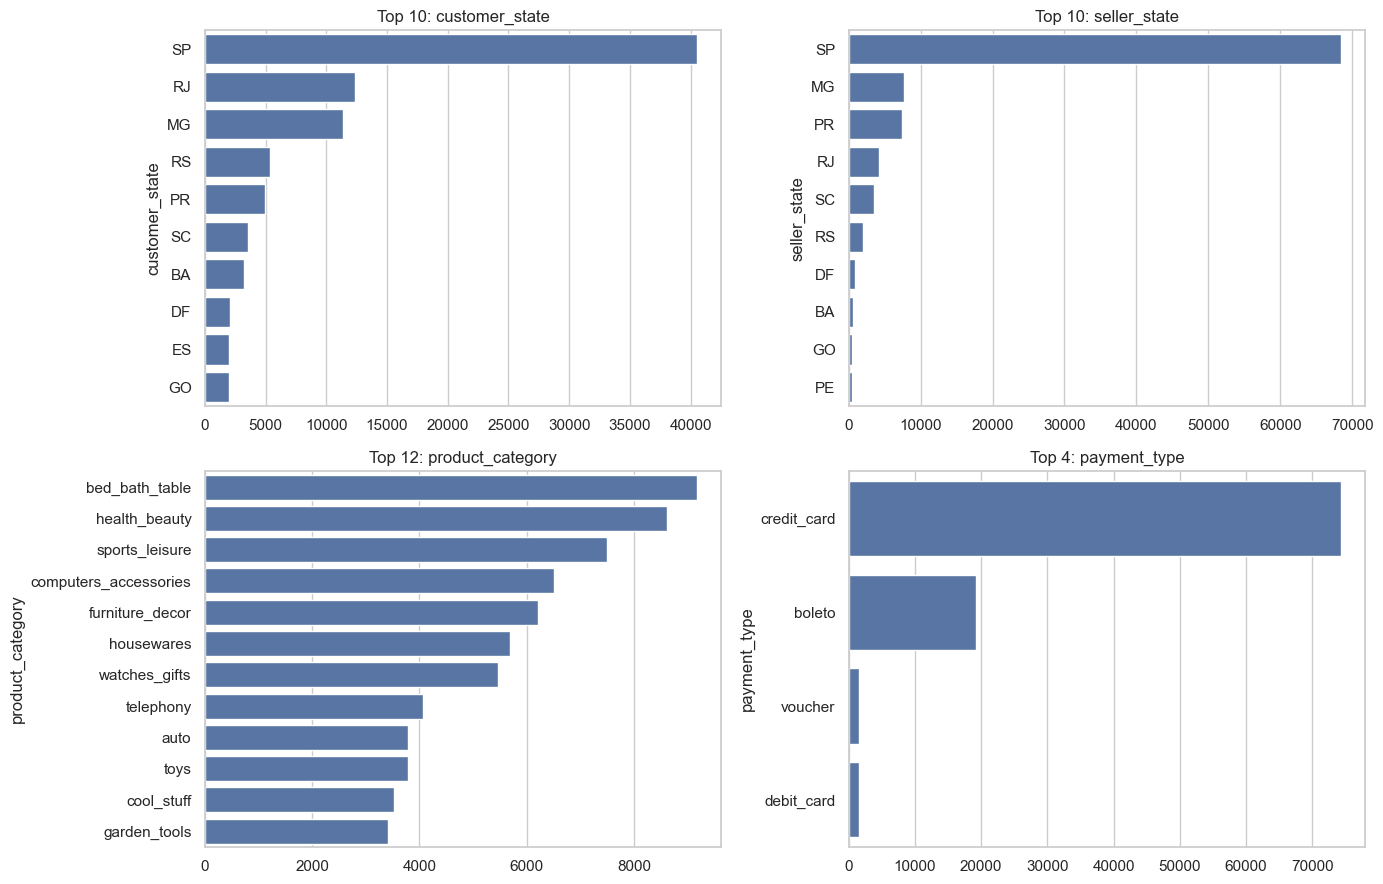

In [8]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.barplot(x=["On-time (0)", "Late (1)"], y=counts.values, color=BLUE, ax=ax)
ax.set_title("Target distribution")
ax.set_ylabel("Orders")
finish(fig, "01_target_distribution.png")

numeric = ["estimated_delivery_days", "distance_km", "total_price", "total_freight",
           "freight_ratio", "total_weight_g", "total_volume_cm3", "shipping_limit_days"]
display(df[numeric].describe(percentiles=[.01, .25, .5, .75, .95, .99]).round(2).T)

fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, col in zip(axes.ravel(), numeric):
    s = df[col].dropna()
    sns.histplot(s[s <= s.quantile(0.99)], bins=40, ax=ax, color=BLUE)
    ax.set_title(col)
fig.suptitle("Numeric features (values above the 99th percentile hidden)")
finish(fig, "02_numeric_distributions.png")

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.histplot(df["days_vs_estimate"].clip(-40, 40), bins=80, ax=ax, color=BLUE)
ax.axvline(0, color="red", ls="--", label="estimated date (right of line = late)")
ax.set_title("Actual minus estimated delivery date, in days (clipped at +/-40)")
ax.legend()
finish(fig, "03_days_vs_estimate.png")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (col, n) in zip(axes.ravel(), [("customer_state", 10), ("seller_state", 10),
                                       ("product_category", 12), ("payment_type", 6)]):
    vc = df[col].value_counts().head(n)
    sns.barplot(x=vc.values, y=vc.index.astype(str), color=BLUE, ax=ax, orient="h")
    ax.set_title(f"Top {len(vc)}: {col}")
finish(fig, "04_categorical_counts.png")

### 3.2 Bivariate analysis: late rate by factor

,orders,late_rate_pct
customer_state,,
AL,397,21.41
MA,717,17.43
SE,335,15.22
PI,476,13.87
CE,1279,13.76
BA,3256,12.16
RJ,12350,12.11
PA,946,11.21
ES,1995,10.73


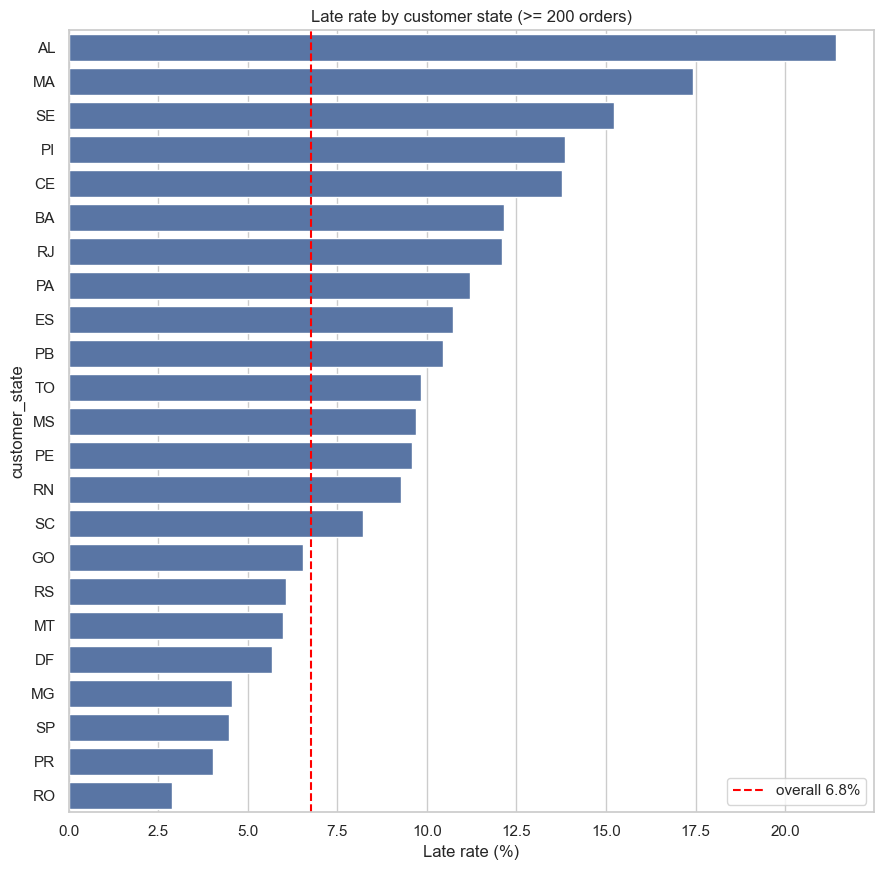

,orders,late_rate_pct
seller_state,,
MA,388,19.07
SP,68415,7.33
RJ,4185,7.19
ES,308,6.17
PR,7429,5.41
DF,803,5.23
SC,3551,4.93
BA,549,4.92
MG,7647,4.84


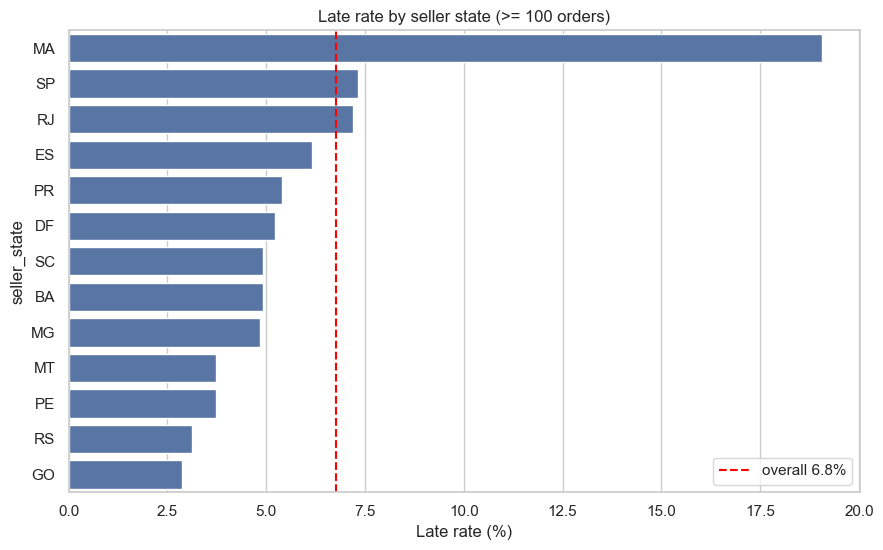

,orders,late_rate_pct
product_category,,
audio,344,11.92
home_confort,370,9.46
baby,2763,8.18
office_furniture,1246,8.11
electronics,2507,7.66
musical_instruments,607,7.58
furniture_living_room,409,7.58
health_beauty,8608,7.54
bed_bath_table,9167,7.52


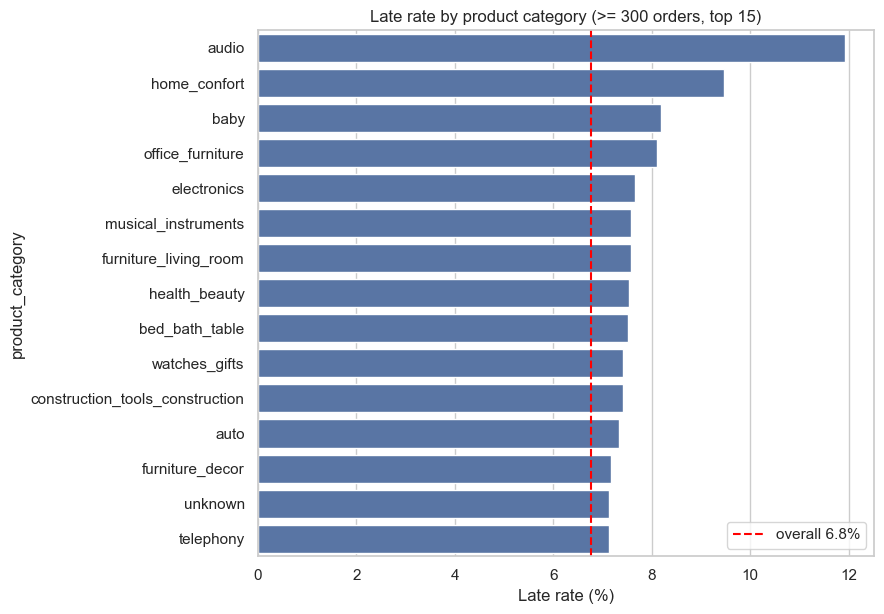

,orders,late_rate_pct
purchase_year_month,,
2016-10,265,0.75
2017-01,750,2.93
2017-02,1653,2.96
2017-03,2546,4.56
2017-04,2303,6.56
2017-05,3545,2.99
2017-06,3135,3.03
2017-07,3872,2.79
2017-08,4193,2.91


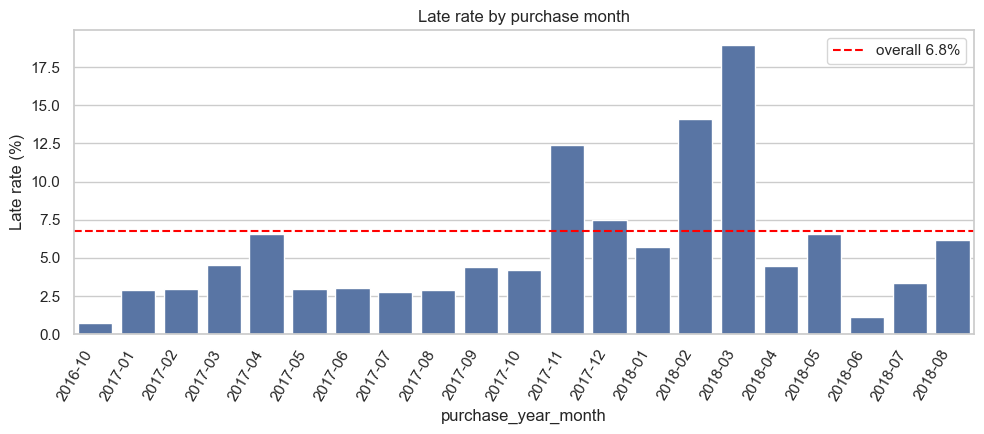

In [9]:
tab = late_rate(df, "customer_state", 200)
display(tab.sort_values("late_rate_pct", ascending=False).head(10))
barh_rate(tab, "Late rate by customer state (>= 200 orders)", "05_late_by_customer_state.png")

tab = late_rate(df, "seller_state", 100)
display(tab.sort_values("late_rate_pct", ascending=False).head(10))
barh_rate(tab, "Late rate by seller state (>= 100 orders)", "06_late_by_seller_state.png")

tab = late_rate(df, "product_category", 300)
display(tab.sort_values("late_rate_pct", ascending=False).head(10))
barh_rate(tab, "Late rate by product category (>= 300 orders, top 15)",
          "07_late_by_category.png", top=15)

tab = late_rate(df, "purchase_year_month", 200)
display(tab)
bar_rate(tab, "Late rate by purchase month", "08_late_by_year_month.png")

distance_km: decile edges [0.0, 34.4, 116.0, 276.5, 347.9, 433.8, 529.7, 694.7, 876.4, 1456.7, 8677.9]


_decile,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0
orders,9600.00,9599.00,9600.00,9598.00,9599.00,9599.00,9599.00,9599.00,9599.00,9600.00
late_rate_pct,4.23,4.83,4.95,6.63,6.64,6.58,7.67,6.73,7.67,11.69


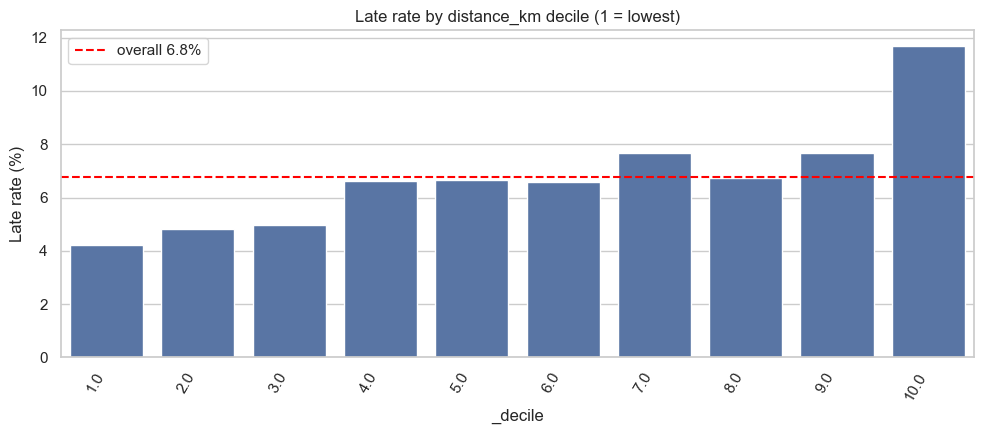

estimated_delivery_days: decile edges [3.0, 14.0, 17.0, 20.0, 22.0, 24.0, 26.0, 28.0, 31.0, 35.0, 156.0]


_decile,1,2,3,4,5,6,7,8,9,10
orders,12002.00,7390.00,11272.00,10467.00,10802.00,9810.00,8410.00,9264.00,8475.00,8578.00
late_rate_pct,6.21,5.72,7.49,8.92,7.79,7.21,7.48,6.65,5.81,3.52


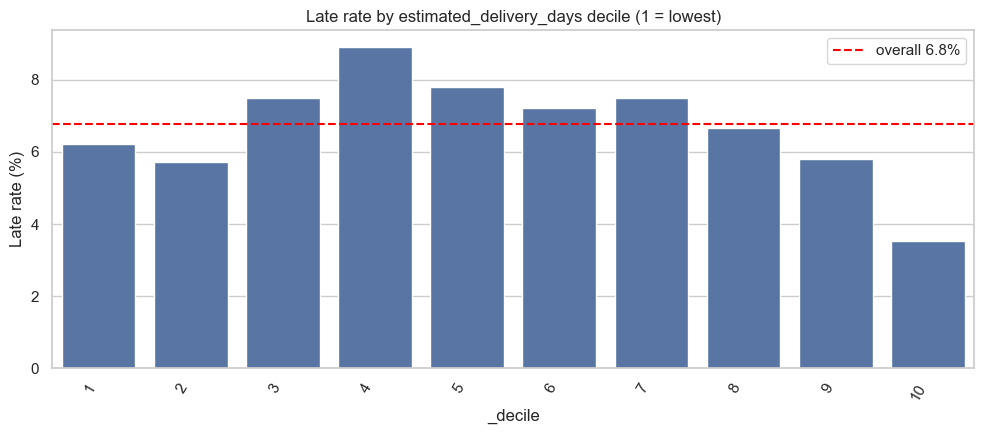

total_freight: decile edges [0.0, 9.3, 12.8, 14.5, 15.6, 17.2, 18.6, 22.0, 27.4, 39.4, 1795.0]


_decile,1,2,3,4,5,6,7,8,9,10
orders,9853.00,9544.0,9572.00,9620.00,9655.00,9725.00,9564.00,9661.00,9629.00,9647.00
late_rate_pct,4.24,4.6,5.25,6.83,7.58,7.63,7.85,7.51,7.76,8.49


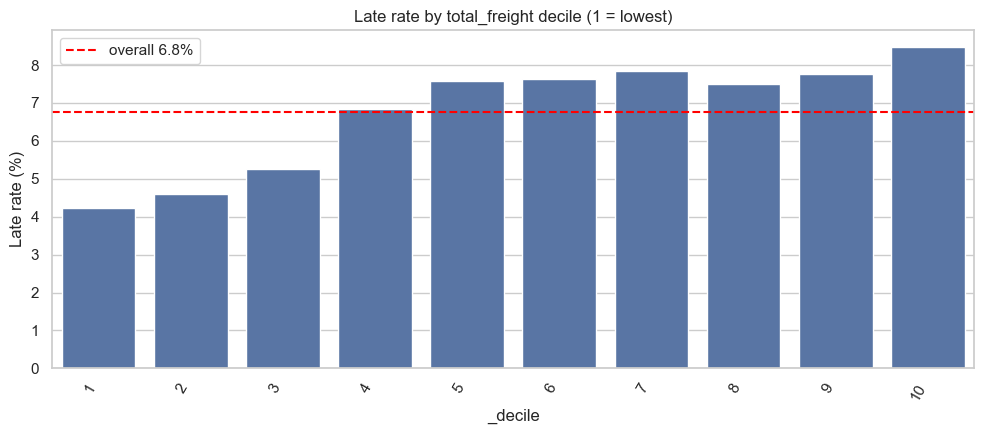

same_state,0,1
orders,61769.00,34701.0
late_rate_pct,8.05,4.5


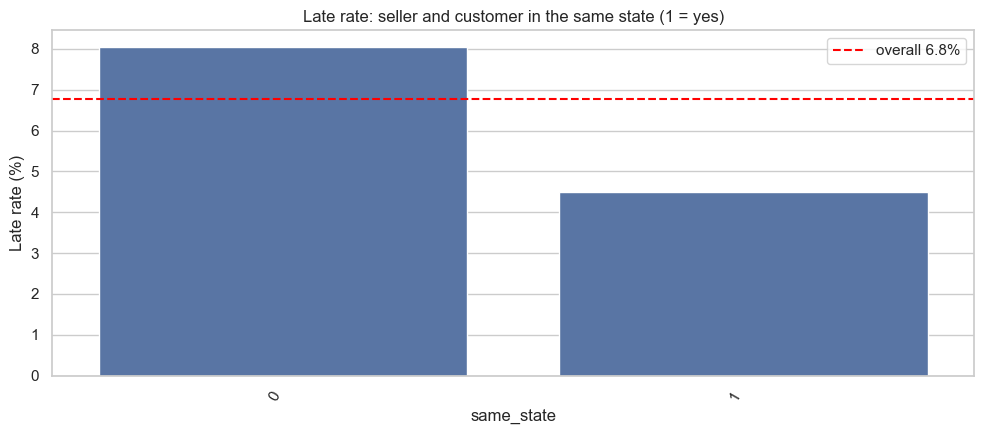

payment_type,boleto,credit_card,debit_card,voucher
orders,19191.00,74296.00,1484.00,1498.00
late_rate_pct,7.32,6.68,5.32,5.81


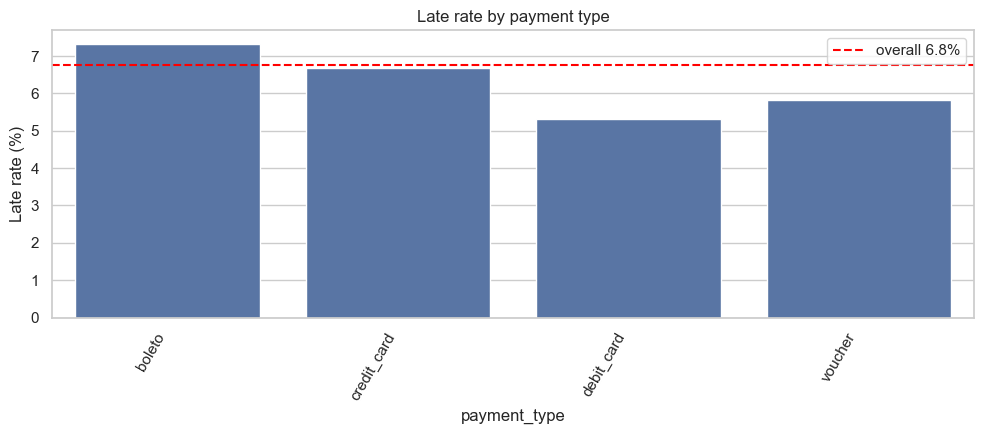

n_sellers_capped,1,2,3
orders,95195.00,1216.00,59.0
late_rate_pct,6.85,1.07,0.0


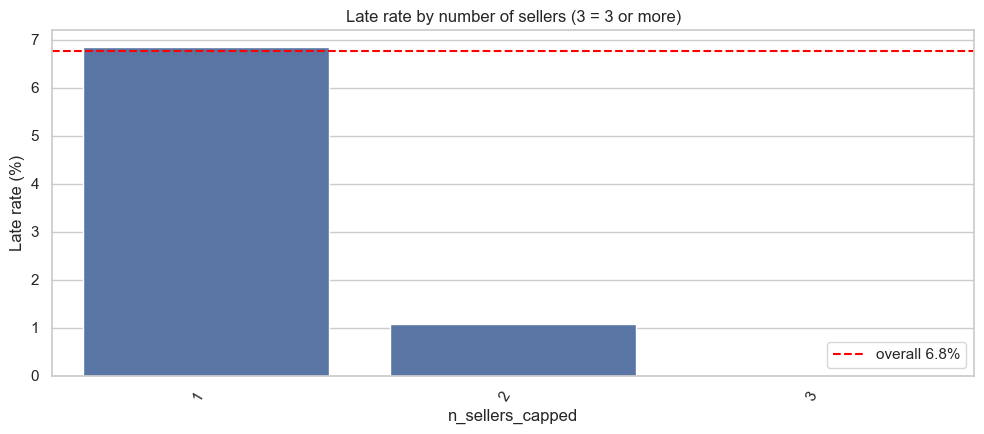

Customer impact (review scores exist only after delivery, so this is analysis only):


,orders,mean_score
is_late,,
0,89443,4.29
1,6381,2.27


Share of 1-2 star reviews (%):


,low_review_pct
is_late,
0,9.23
1,62.36


In [10]:
for col, fname in [("distance_km", "12_late_by_distance.png"),
                   ("estimated_delivery_days", "13_late_by_estimated_days.png"),
                   ("total_freight", "14_late_by_freight.png")]:
    bins, edges = pd.qcut(df[col], 10, labels=False, retbins=True, duplicates="drop")
    tab = late_rate(df.assign(_decile=bins + 1), "_decile")
    print(f"{col}: decile edges {np.round(edges, 1).tolist()}")
    display(tab.T)
    bar_rate(tab, f"Late rate by {col} decile (1 = lowest)", fname)

tmp = df.assign(n_sellers_capped=df["n_sellers"].clip(upper=3))
for col, title, fname in [
    ("same_state", "Late rate: seller and customer in the same state (1 = yes)", "18_late_by_same_state.png"),
    ("payment_type", "Late rate by payment type", "17_late_by_payment.png"),
    ("n_sellers_capped", "Late rate by number of sellers (3 = 3 or more)", "19_late_by_n_sellers.png"),
]:
    tab = late_rate(tmp, col, 30)
    display(tab.T)
    bar_rate(tab, title, fname)

r = df.dropna(subset=["review_score"])
print("Customer impact (review scores exist only after delivery, so this is analysis only):")
display(r.groupby(TARGET)["review_score"].agg(orders="size", mean_score="mean").round(2))
print("Share of 1-2 star reviews (%):")
display((r.assign(low=r["review_score"] <= 2).groupby(TARGET)["low"].mean() * 100).round(2).to_frame("low_review_pct"))

### 3.3 Multivariate analysis

,corr_with_is_late
distance_km,0.076
same_state,-0.068
estimated_delivery_days,-0.033
total_freight,0.031
purchase_month,-0.030
n_sellers,-0.026
n_products,-0.022
total_weight_g,0.020
total_price,0.018
n_items,-0.015


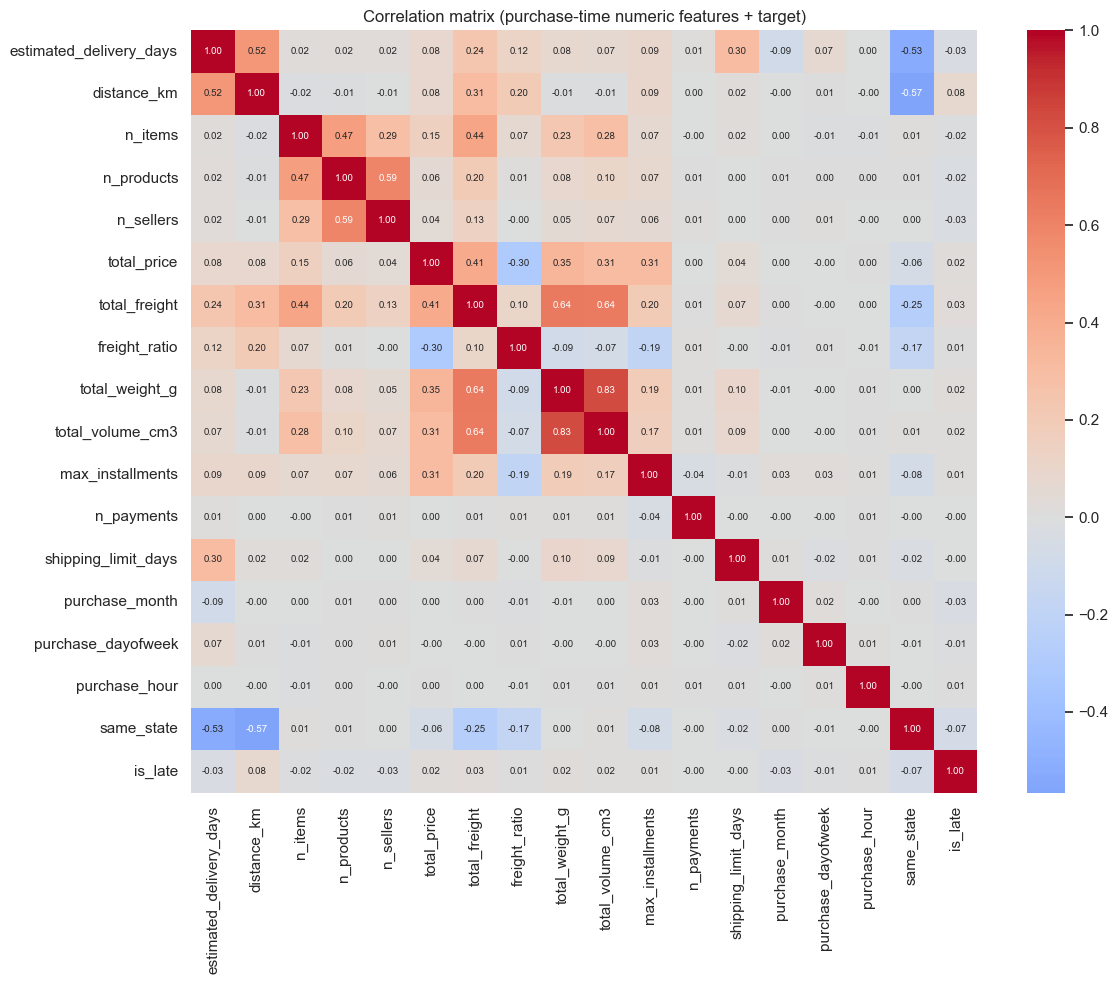

Distance quintile edges (km): [0.0, 116.0, 348.0, 530.0, 876.0, 8678.0]
Promised-days quintile edges: [3.0, 17.0, 22.0, 26.0, 31.0, 156.0]


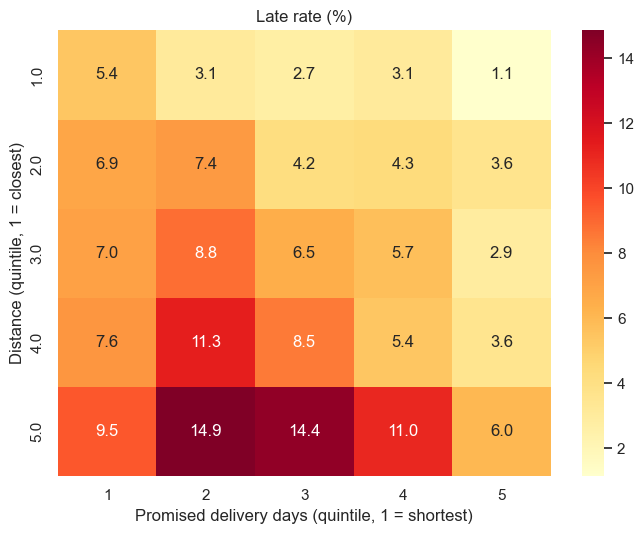

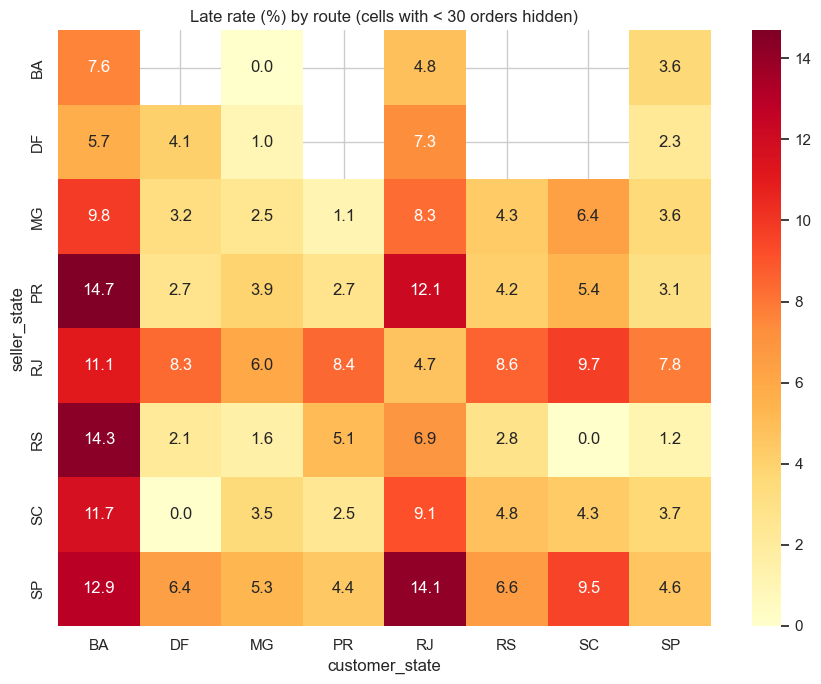

Sellers: 2,960; with >= 30 orders: 621


,late_rate_pct
count,621.00
mean,6.60
std,4.99
min,0.00
25%,3.17
50%,5.56
75%,9.09
max,34.29


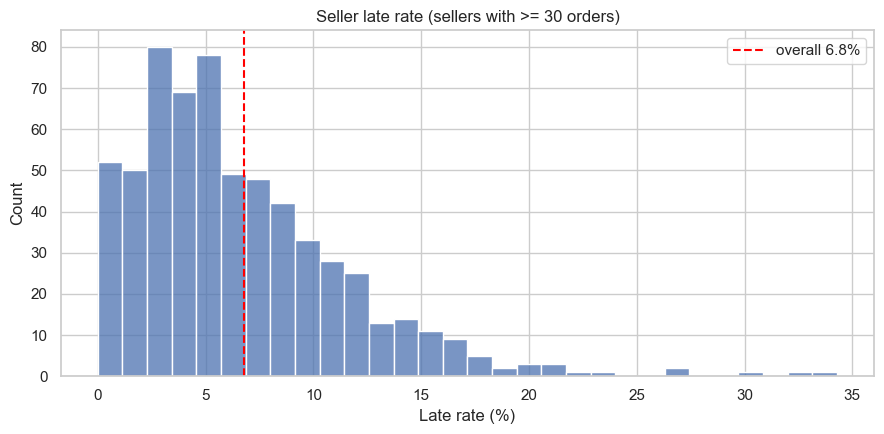

In [11]:
corr = df[NUMERIC_FEATURES + [TARGET]].corr(numeric_only=True)
display(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_frame("corr_with_is_late"))
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", annot_kws={"size": 7}, cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix (purchase-time numeric features + target)")
finish(fig, "22_correlation_heatmap.png")

d_bin, d_edges = pd.qcut(df["distance_km"], 5, labels=False, retbins=True, duplicates="drop")
e_bin, e_edges = pd.qcut(df["estimated_delivery_days"], 5, labels=False, retbins=True, duplicates="drop")
print("Distance quintile edges (km):", np.round(d_edges, 0).tolist())
print("Promised-days quintile edges:", np.round(e_edges, 0).tolist())
pivot = df.assign(dist_q=d_bin + 1, est_q=e_bin + 1).pivot_table(
    index="dist_q", columns="est_q", values=TARGET, aggfunc="mean") * 100
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="YlOrRd", ax=ax)
ax.set_xlabel("Promised delivery days (quintile, 1 = shortest)")
ax.set_ylabel("Distance (quintile, 1 = closest)")
ax.set_title("Late rate (%)")
finish(fig, "23_distance_x_promised_days.png")

top_c = df["customer_state"].value_counts().head(8).index
top_s = df["seller_state"].value_counts().head(8).index
sub = df[df["customer_state"].isin(top_c) & df["seller_state"].isin(top_s)]
cnt = pd.crosstab(sub["seller_state"], sub["customer_state"])
rate = pd.crosstab(sub["seller_state"], sub["customer_state"], values=sub[TARGET], aggfunc="mean") * 100
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(rate.where(cnt >= 30), annot=True, fmt=".1f", cmap="YlOrRd", ax=ax)
ax.set_title("Late rate (%) by route (cells with < 30 orders hidden)")
finish(fig, "24_route_heatmap.png")

seller = df.groupby("seller_id")[TARGET].agg(orders="size", late_orders="sum")
seller["late_rate_pct"] = (seller["late_orders"] / seller["orders"] * 100).round(2)
big = seller[seller["orders"] >= 30]
print(f"Sellers: {len(seller):,}; with >= 30 orders: {len(big):,}")
display(big["late_rate_pct"].describe().round(2).to_frame("late_rate_pct"))
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(big["late_rate_pct"], bins=30, color=BLUE, ax=ax)
ax.axvline(OVERALL, color="red", ls="--", label=f"overall {OVERALL:.1f}%")
ax.set_title("Seller late rate (sellers with >= 30 orders)")
ax.set_xlabel("Late rate (%)")
ax.legend()
finish(fig, "25_seller_late_rate_distribution.png")

### 3.4 Insights and hypotheses from the findings

1. **Lateness is mostly a distance and route problem.** The farthest distance decile is late 11.7% of the time against 4.2% for the closest. Cross-state orders are late 8.1% of the time against 4.5% for same-state orders. Northern and north-eastern customer states are worst (AL 21.4%, MA 17.4%, SE 15.2%, CE 13.8%), and RJ combines a high rate (12.1%) with a large volume.
2. **Delays come in waves, not in a stable seasonal pattern.** November 2017 was 12.4% late, February 2018 14.1% and March 2018 19.0%, while June 2018 was only 1.2%. The same calendar month behaves very differently in different years (March: 4.6% in 2017, 19.0% in 2018). Hypothesis: the November peak is linked to Black Friday volume; the Feb–Mar 2018 spike looks like a one-off operational disruption, because months with similar volume were not late.
3. **The promised delivery window is not scaled to distance.** For the farthest orders the late rate is about 14.9% when 17–22 days are promised and 6.1% when 31 days or more are promised. Hypothesis: promises are too tight for far deliveries, an interaction a linear model cannot capture without help.
4. **Seller reliability varies widely.** Among sellers with at least 30 orders the median late rate is 5.6%, the 75th percentile 9.1% and the worst ten sellers reach 20.6–34.3%. These rates rest on 35–94 orders each, so part of the spread is noise; we check this on held-out data in section 8.
5. **Late delivery hurts satisfaction directly.** Late orders average a review score of 2.27 against 4.29, and 62.4% of them get 1–2 stars against 9.2% for on-time orders.

Weak factors: weekday, hour of day and payment type barely move the late rate, and no numeric feature has a correlation with lateness above 0.08. We should therefore expect a useful but modest model.

## 4. Data preprocessing

**Time-based split instead of a random split.** Late orders cluster in specific weeks, and the deployed model must predict *future* orders. So orders purchased before **2018-06-01** are used for training and orders from that date on form the untouched test set. Training orders that were bought before the cut-off but delivered after it are **purged**, because their label would not be known yet on the cut-off date.

**Pipeline decisions** (all fitted on training data only, inside a scikit-learn `Pipeline`):
- `purchase_month` is dropped: each calendar month is seen only once or twice and behaves differently each year, so the model would memorise one-off events.
- Missing numeric values: median imputation. Missing categories: a `"missing"` label.
- Outliers: each numeric feature is clipped at the 1st and 99th percentile learned from the training data (custom `QuantileClipper`).
- Skewed money, weight and volume features get `log1p`; all numeric features are standardised.
- Categorical features are one-hot encoded; categories with fewer than 100 training orders share one "infrequent" bucket, and unseen categories do not crash prediction.
- Seller identity is **not** a feature (a seller's late rate would have to be computed from training labels only). Duplicates: none exist at order level.

In [12]:
train, test, purged = time_based_split(df)
X_train, y_train = split_xy(train)
X_test, y_test = split_xy(test)

print(f"Duplicated order_id: {int(df['order_id'].duplicated().sum())}   "
      f"Fully duplicated rows: {int(df.duplicated().sum())}")
print(f"Purged from training (bought before the cut-off, delivered after it): {purged:,}")
display(pd.DataFrame([{
    "set": name, "orders": len(p), "late": int(p[TARGET].sum()),
    "late_rate_pct": round(p[TARGET].mean() * 100, 2),
    "first_purchase": p["order_purchase_timestamp"].min().date(),
    "last_purchase": p["order_purchase_timestamp"].max().date(),
} for name, p in (("train", train), ("test", test))]))

checks = {
    "no analysis-only column is a model feature": not set(MODEL_FEATURES) & set(ANALYSIS_ONLY),
    "no id column is a model feature": not set(MODEL_FEATURES) & set(ID_COLUMNS),
    "target is not a model feature": TARGET not in MODEL_FEATURES,
    "every training purchase is before the test period":
        train["order_purchase_timestamp"].max() < test["order_purchase_timestamp"].min(),
    "every training delivery happened before the test period":
        train["order_delivered_customer_date"].max() < TEST_START,
    "no order appears in both sets": not set(train["order_id"]) & set(test["order_id"]),
}
for name, ok in checks.items():
    print(f"[{'OK' if ok else 'FAIL'}] {name}")
assert all(checks.values()), "A leakage check failed"
print(f"\nModel features ({len(MODEL_FEATURES)}): {MODEL_FEATURES}")

Duplicated order_id: 0   Fully duplicated rows: 0
Purged from training (bought before the cut-off, delivered after it): 2,438


,set,orders,late,late_rate_pct,first_purchase,last_purchase
0,train,75429,5368,7.12,2016-09-15,2018-05-29
1,test,18603,672,3.61,2018-06-01,2018-08-29


[OK] no analysis-only column is a model feature
[OK] no id column is a model feature
[OK] target is not a model feature
[OK] every training purchase is before the test period
[OK] every training delivery happened before the test period
[OK] no order appears in both sets

Model features (20): ['estimated_delivery_days', 'distance_km', 'n_items', 'n_products', 'n_sellers', 'total_price', 'total_freight', 'freight_ratio', 'total_weight_g', 'total_volume_cm3', 'max_installments', 'n_payments', 'shipping_limit_days', 'purchase_dayofweek', 'purchase_hour', 'same_state', 'customer_state', 'seller_state', 'product_category', 'payment_type']


**Why is the late rate in the training data lower than in validation windows?** Late orders take longer to arrive, so on a given cut-off date more of them are still in transit and have no label yet. The table below checks this. The "in transit" labels are shown for this diagnostic only and are never used for training.

In [13]:
bought = df["order_purchase_timestamp"]
rows = []
for c in FOLD_CUTOFFS + [TEST_START]:
    before = df[bought < c]
    known = before[before["order_delivered_customer_date"] < c]
    transit = before[before["order_delivered_customer_date"] >= c]
    rows.append({
        "cutoff": c.date(), "bought_before": len(before),
        "late_pct_label_known": round(known[TARGET].mean() * 100, 2),
        "in_transit": len(transit),
        "late_pct_in_transit": round(transit[TARGET].mean() * 100, 2),
    })
display(pd.DataFrame(rows))

,cutoff,bought_before,late_pct_label_known,in_transit,late_pct_in_transit
0,2017-09-01,22264,2.91,1401,11.78
1,2017-12-01,38180,3.34,4188,21.75
2,2018-03-01,57317,5.05,3673,29.27
3,2018-06-01,77867,7.12,2438,20.26


**The preprocessor, fitted on the training set only.** The test set is only transformed, using the training statistics.

In [14]:
pre = build_preprocessor()
display(pre)
Xt_train = pre.fit_transform(X_train)     # fit on TRAIN only
Xt_test = pre.transform(X_test)           # TEST is only transformed
print(f"Input features: {X_train.shape[1]}  ->  transformed columns: {Xt_train.shape[1]}")
print(f"Train: {Xt_train.shape}   Test: {Xt_test.shape}")
print(f"NaN left in train: {int(np.isnan(Xt_train).sum())}   in test: {int(np.isnan(Xt_test).sum())}")

ColumnTransformer(transformers=[('log_num',
                                 Pipeline(steps=[('clip', QuantileClipper()),
                                                 ('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('log',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<ufunc 'log1p'>)),
                                                 ('scale', StandardScaler())]),
                                 ['total_price', 'total_freight',
                                  'freight_ratio', 'total_weight_g',
                                  'total_volume_cm3']),
                                ('num',
                                 Pipeline(steps=[('c...
                                  'shipping_limit_days', 'purchase_dayofweek',
                                  'purchase_hour', 'same_state']),
                                ('cat',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(fill_value='missing',
                                                                strategy='constant')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                min_frequency=100,
                                                                sparse_output=False))]),
                                 ['customer_state', 'seller_state',
                                  'product_category', 'payment_type'])],
                  verbose_feature_names_out=False)

Input features: 20  ->  transformed columns: 108
Train: (75429, 108)   Test: (18603, 108)
NaN left in train: 0   in test: 0


## 5. Machine learning modeling

Four models are compared, each wrapped in a `Pipeline` (preprocessor + model) so that preprocessing is refitted inside every validation fold:

| Model | What it is | Strength | Weakness |
|---|---|---|---|
| **Dummy (prior)** | Always outputs the training late rate | The floor every model must beat | Learns nothing |
| **Logistic Regression** | Linear model of the log-odds of being late | Simple, fast, explainable | Cannot capture interactions by itself |
| **Random Forest** | 300 averaged decision trees | Finds non-linear effects and interactions | Slower, larger saved file |
| **XGBoost** | Small trees built one after another, each correcting the previous | Often the strongest on tabular data | Needs tuning |

**Imbalance** (about 7% late) is handled with class weights (`class_weight`, `scale_pos_weight`), not with synthetic samples.

**Validation.** Three expanding time windows *inside the training set* (validation starts 2017-09-01, 2017-12-01 and 2018-03-01). Each fold is fitted only on orders bought **and delivered** before its window. **The test set is not used in sections 5 and 6.**

In [15]:
folds = make_time_folds(train)
fold_bought = train["order_purchase_timestamp"]
display(pd.DataFrame([{
    "fold": i, "fit_orders": len(f), "fit_late_pct": round(y_train.iloc[f].mean() * 100, 2),
    "val_orders": len(v), "val_late_pct": round(y_train.iloc[v].mean() * 100, 2),
    "val_from": fold_bought.iloc[v].min().date(), "val_to": fold_bought.iloc[v].max().date(),
} for i, (f, v) in enumerate(folds, 1)]))

records = []
for name in MODEL_NAMES:
    for i, (fit_idx, val_idx) in enumerate(folds, 1):
        pipe = build_pipeline(name, y_train.iloc[fit_idx])
        pipe.fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
        proba = pipe.predict_proba(X_train.iloc[val_idx])[:, 1]
        rec = {"model": name, "fold": i}
        rec.update(evaluate_scores(y_train.iloc[val_idx], proba))
        records.append(rec)
    print(f"done: {name}")
cv5 = pd.DataFrame(records)
cv5["pr_auc_x_baseline"] = cv5["pr_auc"] / cv5["prevalence"]
display(cv5[["model", "fold", "prevalence", "pr_auc", "pr_auc_x_baseline", "roc_auc",
             "recall_top10", "lift_top10", "f1_05"]].round(3))

,fold,fit_orders,fit_late_pct,val_orders,val_late_pct,val_from,val_to
0,1,20863,2.91,15916,8.00,2017-09-01,2017-11-30
1,2,33992,3.34,19132,9.07,2017-12-01,2018-02-28
2,3,53644,5.05,18117,8.77,2018-03-01,2018-05-29


done: Dummy (prior)
done: Logistic Regression
done: Random Forest
done: XGBoost


,model,fold,prevalence,pr_auc,pr_auc_x_baseline,roc_auc,recall_top10,lift_top10,f1_05
0,Dummy (prior),1,0.080,0.080,1.000,0.500,0.104,1.045,0.000
1,Dummy (prior),2,0.091,0.091,1.000,0.500,0.104,1.038,0.000
2,Dummy (prior),3,0.088,0.088,1.000,0.500,0.106,1.064,0.000
3,Logistic Regression,1,0.080,0.119,1.485,0.611,0.189,1.893,0.177
4,Logistic Regression,2,0.091,0.147,1.624,0.637,0.192,1.920,0.217
5,Logistic Regression,3,0.088,0.206,2.349,0.715,0.309,3.091,0.252
6,Random Forest,1,0.080,0.107,1.334,0.584,0.148,1.484,0.109
7,Random Forest,2,0.091,0.138,1.526,0.625,0.172,1.718,0.165
8,Random Forest,3,0.088,0.205,2.341,0.700,0.305,3.047,0.279
9,XGBoost,1,0.080,0.106,1.327,0.589,0.150,1.500,0.165


,pr_auc,pr_auc_x_baseline,roc_auc,recall_top10,precision_top10,lift_top10,f1_05
Logistic Regression,0.157 +/- 0.044,1.819 +/- 0.464,0.654 +/- 0.054,0.230 +/- 0.068,0.199 +/- 0.064,2.301 +/- 0.684,0.215 +/- 0.038
XGBoost,0.153 +/- 0.052,1.765 +/- 0.545,0.645 +/- 0.066,0.219 +/- 0.083,0.190 +/- 0.077,2.186 +/- 0.831,0.211 +/- 0.050
Random Forest,0.150 +/- 0.050,1.733 +/- 0.535,0.637 +/- 0.059,0.208 +/- 0.084,0.181 +/- 0.077,2.083 +/- 0.843,0.184 +/- 0.087
Dummy (prior),0.086 +/- 0.006,1.000 +/- 0.000,0.500 +/- 0.000,0.105 +/- 0.001,0.090 +/- 0.006,1.049 +/- 0.014,0.000 +/- 0.000


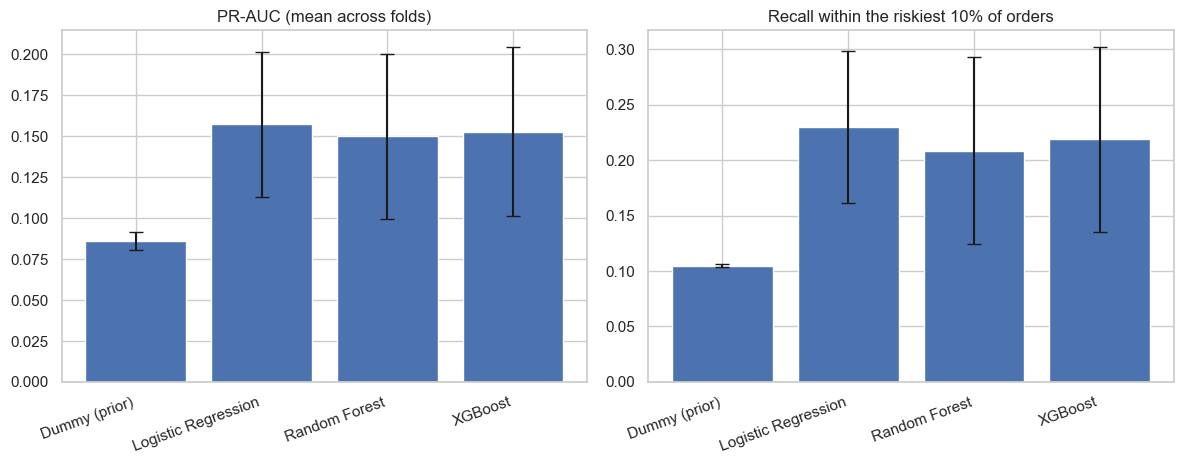

In [16]:
cols = ["pr_auc", "pr_auc_x_baseline", "roc_auc", "recall_top10", "precision_top10", "lift_top10", "f1_05"]
order = cv5.groupby("model")["pr_auc"].mean().sort_values(ascending=False).index
summary = pd.DataFrame({
    m: {c: f"{cv5[cv5.model == m][c].mean():.3f} +/- {cv5[cv5.model == m][c].std():.3f}" for c in cols}
    for m in order}).T
display(summary)

means = cv5.groupby("model")[["pr_auc", "recall_top10"]].agg(["mean", "std"]).loc[MODEL_NAMES]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (c, title) in zip(axes, [("pr_auc", "PR-AUC (mean across folds)"),
                                 ("recall_top10", "Recall within the riskiest 10% of orders")]):
    ax.bar(MODEL_NAMES, means[(c, "mean")], yerr=means[(c, "std")], capsize=5, color=BLUE)
    ax.set_title(title)
    plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
finish(fig, "26_model_comparison.png")

**How to read this table.** `pr_auc_x_baseline` divides PR-AUC by the late rate of the validation fold: 1.0 means no better than guessing, which is exactly where the Dummy sits. A real model must clearly beat the Dummy *and* the fold-to-fold spread (the "+/-"), because the validation windows contain very different periods (for example the November 2017 and March 2018 delay waves).

## 6. Tuning and validation

- `GridSearchCV` for Logistic Regression (12 combinations) and `RandomizedSearchCV` for Random Forest (12 candidates) and XGBoost (30 candidates).
- The **same time-ordered folds** are used and the preprocessor is refitted inside each fold. **Only training data is used.**
- The imbalance weight `scale_pos_weight` is a tuned hyperparameter, so no labels outside the fold are used to set it.

**Selection rule (declared before seeing tuned results):** keep every model whose mean CV PR-AUC is within 0.01 of the best, then choose the one with the highest recall in the riskiest 10% of orders. I chose this because default-model gaps were smaller than the fold-to-fold noise, so a rule based on PR-AUC alone would choose on noise.

In [17]:
TIE_MARGIN = 0.01
searches, rows, all_cv = {}, [], []


def py(v):
    if isinstance(v, np.integer):
        return int(v)
    if isinstance(v, np.floating):
        return round(float(v), 4)
    return v


for name in TUNED_MODELS:
    kind, space, n_iter = SEARCH_SPACES[name]
    common = dict(scoring=SCORING, refit="pr_auc", cv=folds, n_jobs=1, error_score="raise")
    if kind == "grid":
        n_cand = int(np.prod([len(v) for v in space.values()]))
        search = GridSearchCV(base_pipeline(name), space, **common)
    else:
        n_cand = n_iter
        search = RandomizedSearchCV(base_pipeline(name), space, n_iter=n_iter,
                                    random_state=RANDOM_STATE, **common)
    print(f"Tuning {name}: {n_cand} candidates x {len(folds)} folds ...")
    t0 = time.time()
    search.fit(X_train, y_train)
    print(f"  done in {(time.time() - t0) / 60:.1f} min. Best CV PR-AUC: {search.best_score_:.3f}")
    cv = search.cv_results_
    i = search.best_index_
    rows.append({
        "model": name,
        "pr_auc": cv["mean_test_pr_auc"][i], "pr_auc_std": cv["std_test_pr_auc"][i],
        "roc_auc": cv["mean_test_roc_auc"][i],
        "recall_top10": cv["mean_test_recall_top10"][i],
        "fold_pr_auc": [round(cv[f"split{k}_test_pr_auc"][i], 3) for k in range(len(folds))],
        "best_params": {k.replace("model__", ""): py(v) for k, v in search.best_params_.items()},
    })
    searches[name] = search
    part = pd.DataFrame(cv)
    part.insert(0, "model", name)
    all_cv.append(part)

pd.concat(all_cv).to_csv(ROOT / "reports" / "tuning_results.csv", index=False)
res = pd.DataFrame(rows)
default_pr = cv5.groupby("model")["pr_auc"].mean()
res["default_pr_auc"] = res["model"].map(default_pr)
display(res[["model", "pr_auc", "pr_auc_std", "roc_auc", "recall_top10", "default_pr_auc"]]
        .round(3).sort_values("pr_auc", ascending=False))
for r in rows:
    print(f"{r['model']}: PR-AUC per fold {r['fold_pr_auc']}\n    {r['best_params']}")
print("\nNote: the search is scored on the same folds it tunes on, so these scores are slightly "
      "optimistic. The untouched test set in section 7 is the honest measure.")

Tuning Logistic Regression: 12 candidates x 3 folds ...
  done in 0.4 min. Best CV PR-AUC: 0.167
Tuning Random Forest: 12 candidates x 3 folds ...
  done in 2.3 min. Best CV PR-AUC: 0.153
Tuning XGBoost: 30 candidates x 3 folds ...
  done in 1.5 min. Best CV PR-AUC: 0.156


,model,pr_auc,pr_auc_std,roc_auc,recall_top10,default_pr_auc
0,Logistic Regression,0.167,0.038,0.666,0.244,0.157
2,XGBoost,0.156,0.044,0.647,0.221,0.153
1,Random Forest,0.153,0.041,0.637,0.218,0.150


Logistic Regression: PR-AUC per fold [0.126, 0.156, 0.218]
    {'C': 0.03, 'class_weight': None}
Random Forest: PR-AUC per fold [0.108, 0.143, 0.206]
    {'min_samples_leaf': 10, 'max_features': 0.2, 'max_depth': 12, 'class_weight': 'balanced_subsample'}
XGBoost: PR-AUC per fold [0.108, 0.145, 0.214]
    {'colsample_bytree': 0.5324, 'learning_rate': 0.0214, 'max_depth': 5, 'min_child_weight': 7, 'n_estimators': 485, 'reg_lambda': 6.9194, 'scale_pos_weight': 25, 'subsample': 0.7139}

Note: the search is scored on the same folds it tunes on, so these scores are slightly optimistic. The untouched test set in section 7 is the honest measure.


In [18]:
best_pr = res["pr_auc"].max()
tied = res[res["pr_auc"] >= best_pr - TIE_MARGIN].sort_values("recall_top10", ascending=False)
chosen_name = tied.iloc[0]["model"]
chosen = searches[chosen_name]
chosen_row = res[res["model"] == chosen_name].iloc[0]
print(f"Candidates within {TIE_MARGIN} PR-AUC of the best ({best_pr:.3f}): {', '.join(tied['model'])}")
print(f"Selected model: {chosen_name}")

# Out-of-fold scores of the selected configuration (each fold fitted without its own validation window)
oof = []
for i, (fit_idx, val_idx) in enumerate(folds, 1):
    pipe = clone(chosen.best_estimator_)
    pipe.fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
    oof.append(pd.DataFrame({"fold": i, "y": y_train.iloc[val_idx].to_numpy(),
                             "score": pipe.predict_proba(X_train.iloc[val_idx])[:, 1]}))
oof = pd.concat(oof, ignore_index=True)

BUDGETS = [0.05, 0.10, 0.20, 0.30]
biz = []
for frac in BUDGETS:
    vals = np.array([top_k_metrics(g["y"], g["score"], frac) for _, g in oof.groupby("fold")])
    p = vals[:, 0].mean()
    biz.append({"orders_flagged_pct": int(frac * 100), "precision": p, "recall": vals[:, 1].mean(),
                "lift": vals[:, 2].mean(), "false_alarms_per_catch": (1 - p) / p if p > 0 else np.nan})
print("\nBusiness trade-off: how many orders can the marketplace act on? (3 validation folds)")
display(pd.DataFrame(biz).round(3))

Candidates within 0.01 PR-AUC of the best (0.167): Logistic Regression
Selected model: Logistic Regression

Business trade-off: how many orders can the marketplace act on? (3 validation folds)


,orders_flagged_pct,precision,recall,lift,false_alarms_per_catch
0,5,0.231,0.134,2.673,3.333
1,10,0.211,0.244,2.444,3.735
2,20,0.171,0.396,1.980,4.852
3,30,0.147,0.512,1.706,5.786


**Risk tiers.** The tier cut-offs are learned from the out-of-fold validation scores: **High** = riskiest 10%, **Medium** = next 20%, **Low** = the rest. The observed late rate of each tier is reported, so the app can say "orders in this tier were late X% of the time" without overclaiming.

**Probabilities.** Class weighting inflates the raw model scores, so an isotonic calibrator is fitted on the out-of-fold scores (training data only) to convert a score into an estimated late probability. Section 7 checks how well this works on the test set; section 7.3 explains what that check revealed and how the tiers were redefined.

In [19]:
MEDIUM_Q, HIGH_Q = 0.70, 0.90
medium_cut = float(np.quantile(oof["score"], MEDIUM_Q))
high_cut = float(np.quantile(oof["score"], HIGH_Q))


def to_tier(scores):
    scores = np.asarray(scores)
    return np.where(scores >= high_cut, "High", np.where(scores >= medium_cut, "Medium", "Low"))


tiers = (oof.assign(tier=to_tier(oof["score"])).groupby("tier")["y"]
         .agg(orders="size", late_orders="sum", late_rate="mean").reindex(["High", "Medium", "Low"]))
tiers["late_rate_pct"] = (tiers["late_rate"] * 100).round(2)
print(f"Medium cut-off: score >= {medium_cut:.4f}    High cut-off: score >= {high_cut:.4f}")
display(tiers[["orders", "late_orders", "late_rate_pct"]])
print(f"Overall validation late rate: {oof['y'].mean() * 100:.2f}%")

calibrator = IsotonicRegression(out_of_bounds="clip", y_min=0.0, y_max=1.0)
calibrator.fit(oof["score"], oof["y"])

final_pipe = chosen.best_estimator_      # already refitted on the full training set
joblib.dump(final_pipe, MODEL_PATH, compress=3)

meta = {
    "model_name": chosen_name,
    "best_params": chosen_row["best_params"],
    "selection_rule": f"PR-AUC within {TIE_MARGIN} of best, then highest recall in the riskiest 10%",
    "cv_metrics": {"pr_auc_mean": chosen_row["pr_auc"], "pr_auc_std": chosen_row["pr_auc_std"],
                   "roc_auc_mean": chosen_row["roc_auc"], "recall_top10_mean": chosen_row["recall_top10"]},
    "risk_tiers": {"medium_cutoff": medium_cut, "high_cutoff": high_cut,
                   "validation_late_rate_pct": {t: float(tiers.loc[t, "late_rate_pct"]) for t in tiers.index}},
    "train": {"orders": len(train), "late_rate_pct": round(float(y_train.mean() * 100), 2),
              "first_purchase": str(train["order_purchase_timestamp"].min().date()),
              "last_purchase": str(train["order_purchase_timestamp"].max().date())},
    "test_start": str(TEST_START.date()),
    "trained_on_test_set": False,
    "model_features": MODEL_FEATURES,
    "versions": {"python": platform.python_version(),
                 **{p: version(p) for p in ("scikit-learn", "xgboost", "pandas", "numpy")}},
}
(MODELS_DIR / "model_metadata.json").write_text(json.dumps(meta, indent=2, default=py), encoding="utf-8")

reloaded = joblib.load(MODEL_PATH)
same = np.allclose(final_pipe.predict_proba(X_train.head(500)), reloaded.predict_proba(X_train.head(500)))
print(f"\nSaved {MODEL_PATH.name}: {MODEL_PATH.stat().st_size / 1_048_576:.1f} MB   "
      f"reload check: {'OK' if same else 'FAIL'}")

Medium cut-off: score >= 0.0419    High cut-off: score >= 0.0678


,orders,late_orders,late_rate_pct
tier,,,
High,5317,1050,19.75
Medium,10633,1200,11.29
Low,37215,2346,6.30


Overall validation late rate: 8.64%

Saved late_delivery_pipeline.joblib: 0.0 MB   reload check: OK


## 7. Model evaluation on the untouched test set

This is the first and only time the test set (orders purchased from 2018-06-01) is used to score the model. **Nothing is tuned on it.** The two alert cut-offs come from the *validation* scores in section 6.

**Reading the results:** the test period has a lower late rate than the training period, and PR-AUC scales with the late rate. A random guesser would score a PR-AUC equal to the test late rate (3.61%), so compare every PR-AUC value with that baseline, not with the validation numbers.

Selected model: Logistic Regression
Test orders: 18,603   late: 672   late rate: 3.61%


,Selected model,Dummy baseline
PR-AUC,0.065,0.036
ROC-AUC,0.634,0.500


PR-AUC is 1.80x the random-guess baseline (0.036).


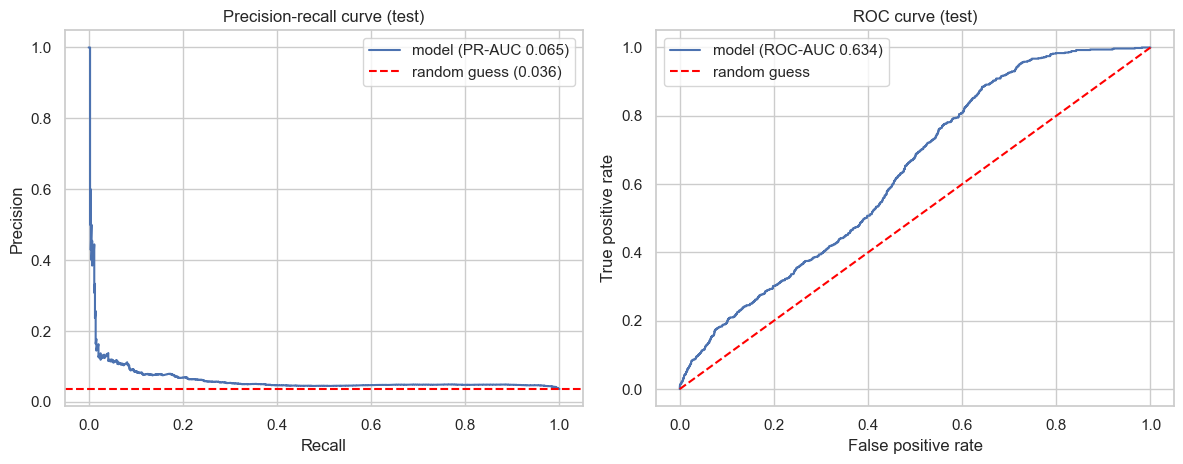

In [20]:
final = joblib.load(MODEL_PATH)                       # the saved artifact, exactly as the app will use it
dummy = build_pipeline("Dummy (prior)").fit(X_train, y_train)
proba = final.predict_proba(X_test)[:, 1]
proba_dummy = dummy.predict_proba(X_test)[:, 1]
prev = y_test.mean()
print(f"Selected model: {chosen_name}")
print(f"Test orders: {len(y_test):,}   late: {int(y_test.sum()):,}   late rate: {prev * 100:.2f}%")

metrics = {
    "model": chosen_name,
    "test_orders": int(len(y_test)), "test_late": int(y_test.sum()), "test_late_rate_pct": round(prev * 100, 2),
    "pr_auc": float(average_precision_score(y_test, proba)),
    "roc_auc": float(roc_auc_score(y_test, proba)),
    "pr_auc_dummy": float(average_precision_score(y_test, proba_dummy)),
    "roc_auc_dummy": float(roc_auc_score(y_test, proba_dummy)),
}
display(pd.DataFrame({"Selected model": [metrics["pr_auc"], metrics["roc_auc"]],
                      "Dummy baseline": [metrics["pr_auc_dummy"], metrics["roc_auc_dummy"]]},
                     index=["PR-AUC", "ROC-AUC"]).round(3))
print(f"PR-AUC is {metrics['pr_auc'] / prev:.2f}x the random-guess baseline ({prev:.3f}).")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
pr_p, pr_r, _ = precision_recall_curve(y_test, proba)
axes[0].plot(pr_r, pr_p, color=BLUE, label=f"model (PR-AUC {metrics['pr_auc']:.3f})")
axes[0].axhline(prev, color="red", ls="--", label=f"random guess ({prev:.3f})")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision"); axes[0].set_title("Precision-recall curve (test)")
axes[0].legend()
fpr, tpr, _ = roc_curve(y_test, proba)
axes[1].plot(fpr, tpr, color=BLUE, label=f"model (ROC-AUC {metrics['roc_auc']:.3f})")
axes[1].plot([0, 1], [0, 1], color="red", ls="--", label="random guess")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve (test)"); axes[1].legend()
finish(fig, "27_pr_roc_curves.png")

### 7.1 Confusion matrix, precision, recall, F1 and classification report

Two operating points, both fixed **before** looking at the test set: the *High* cut-off (the riskiest 10% on validation) and the *Medium* cut-off (the riskiest 30% on validation). Because the test period is calmer, the share of test orders flagged can differ from 10% and 30%.

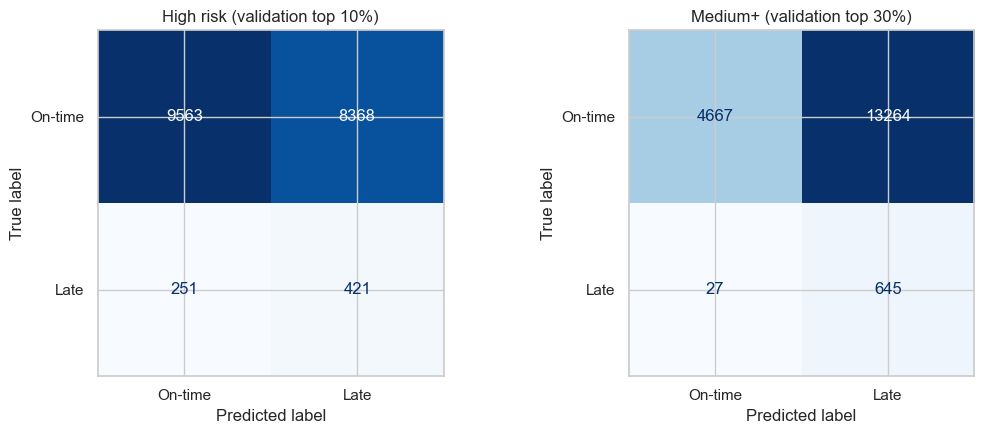

,operating point,cut-off,orders flagged %,precision,recall,F1
0,High risk (validation top 10%),0.068,47.2,0.048,0.626,0.089
1,Medium+ (validation top 30%),0.042,74.8,0.046,0.960,0.088



Classification report: High risk (validation top 10%)
              precision    recall  f1-score   support

     On-time      0.974     0.533     0.689     17931
        Late      0.048     0.626     0.089       672

    accuracy                          0.537     18603
   macro avg      0.511     0.580     0.389     18603
weighted avg      0.941     0.537     0.668     18603


Classification report: Medium+ (validation top 30%)
              precision    recall  f1-score   support

     On-time      0.994     0.260     0.413     17931
        Late      0.046     0.960     0.088       672

    accuracy                          0.286     18603
   macro avg      0.520     0.610     0.251     18603
weighted avg      0.960     0.286     0.401     18603



In [21]:
operating = {"High risk (validation top 10%)": high_cut, "Medium+ (validation top 30%)": medium_cut}
op_rows, fig_axes = [], plt.subplots(1, 2, figsize=(11, 4.5))
fig, axes = fig_axes
for ax, (label, cut) in zip(axes, operating.items()):
    pred = (proba >= cut).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["On-time", "Late"],
                                            ax=ax, colorbar=False, values_format="d", cmap="Blues")
    ax.set_title(label)
    op_rows.append({"operating point": label, "cut-off": round(cut, 4),
                    "orders flagged %": round(pred.mean() * 100, 1),
                    "precision": precision_score(y_test, pred, zero_division=0),
                    "recall": recall_score(y_test, pred, zero_division=0),
                    "F1": f1_score(y_test, pred, zero_division=0)})
finish(fig, "28_confusion_matrices.png")
op = pd.DataFrame(op_rows)
display(op.round(3))
metrics["operating_points"] = op.round(4).to_dict(orient="records")

for label, cut in operating.items():
    print(f"\nClassification report: {label}")
    print(classification_report(y_test, (proba >= cut).astype(int),
                                target_names=["On-time", "Late"], digits=3, zero_division=0))

In [22]:
test_biz = []
for frac in BUDGETS:
    p, r, lift = top_k_metrics(y_test, proba, frac)
    test_biz.append({"orders_flagged_pct": int(frac * 100), "precision": p, "recall": r, "lift": lift,
                     "false_alarms_per_catch": (1 - p) / p if p > 0 else np.nan})
print("Test set: what acting on the riskiest X% of orders buys")
display(pd.DataFrame(test_biz).round(3))
metrics["budget_table"] = pd.DataFrame(test_biz).round(4).to_dict(orient="records")

Test set: what acting on the riskiest X% of orders buys


,orders_flagged_pct,precision,recall,lift,false_alarms_per_catch
0,5,0.082,0.113,2.262,11.237
1,10,0.069,0.190,1.905,13.531
2,20,0.053,0.293,1.466,17.888
3,30,0.047,0.394,1.314,20.060


### 7.2 Probability calibration and risk tiers on the test set

Test late rate:                    3.61%
Mean calibrated probability:       17.15%
Brier score, calibrated model:     0.0647
Brier score, constant train rate:  0.0360  (lower is better)

Observed late rate in each risk tier (test) against the validation rate used in the app:


,orders,late_orders,late_rate_pct,mean_calibrated_prob_pct,share_of_late_orders_pct
tier,,,,,
High,8789,421,4.79,26.18,62.6
Medium,5120,224,4.38,11.72,33.3
Low,4694,27,0.58,6.17,4.0


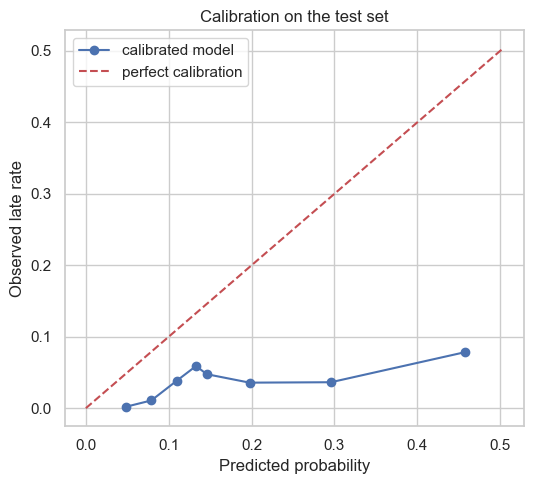

In [23]:
cal = calibrator.predict(proba)
const = np.full(len(y_test), y_train.mean())
print(f"Test late rate:                    {prev * 100:.2f}%")
print(f"Mean calibrated probability:       {cal.mean() * 100:.2f}%")
print(f"Brier score, calibrated model:     {brier_score_loss(y_test, cal):.4f}")
print(f"Brier score, constant train rate:  {brier_score_loss(y_test, const):.4f}  (lower is better)")

tier_test = pd.DataFrame({"tier": to_tier(proba), "y": y_test.to_numpy(), "prob": cal})
tt = (tier_test.groupby("tier").agg(orders=("y", "size"), late_orders=("y", "sum"),
                                    late_rate=("y", "mean"), mean_calibrated_prob=("prob", "mean"))
      .reindex(["High", "Medium", "Low"]))
tt["late_rate_pct"] = (tt["late_rate"] * 100).round(2)
tt["mean_calibrated_prob_pct"] = (tt["mean_calibrated_prob"] * 100).round(2)
tt["share_of_late_orders_pct"] = (tt["late_orders"] / tt["late_orders"].sum() * 100).round(1)
print("\nObserved late rate in each risk tier (test) against the validation rate used in the app:")
display(tt[["orders", "late_orders", "late_rate_pct", "mean_calibrated_prob_pct", "share_of_late_orders_pct"]])
metrics["tiers_test"] = tt[["orders", "late_orders", "late_rate_pct", "mean_calibrated_prob_pct",
                            "share_of_late_orders_pct"]].reset_index().to_dict(orient="records")

frac_pos, mean_pred = calibration_curve(y_test, cal, n_bins=8, strategy="quantile")
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(mean_pred, frac_pos, "o-", color=BLUE, label="calibrated model")
lim = max(mean_pred.max(), frac_pos.max()) * 1.1
ax.plot([0, lim], [0, lim], "r--", label="perfect calibration")
ax.set_xlabel("Predicted probability"); ax.set_ylabel("Observed late rate")
ax.set_title("Calibration on the test set"); ax.legend()
finish(fig, "29_calibration.png")

### 7.3 Why the validation cut-offs and probabilities failed, and a more robust tier definition

**What went wrong in the first version (7.1 and 7.2).** The cut-offs were meant to flag 10% and 30% of orders, but on the test set they flagged **47.2%** and **74.8%**. The "High" and "Medium" tiers had almost the same late rate (4.79% and 4.38%), and the calibrated probabilities averaged **17.2%** against a real late rate of **3.61%**, with a Brier score (0.0647) worse than simply predicting the training late rate (0.0360).

**Two possible causes (hypotheses, separated by the table below).**
1. *A mismatch in how the cut-offs were built.* They were learned from out-of-fold scores of models fitted on earlier, smaller windows (whose training data was 2.9% to 5.1% late), but the deployed model is fitted on all training data (7.12% late). The scores of a Logistic Regression shift with the late rate of its training data, so cut-offs from one model do not fit another.
2. *Real drift.* The test period has a lower late rate and, as section 4 showed, shorter promised delivery windows, which this model treats as risky.

**More robust definition.** Tier cut-offs are now the 70th and 90th percentile of the **deployed model's own scores on the training set**. This keeps the tiers tied to the model that is actually used. For a heavily regularised Logistic Regression these in-sample scores are close to out-of-sample scores. The model's probabilities are used directly, because it was trained without class weights.

**Transparency note.** This redefinition was made *after* seeing the test result of the first version. The model itself is unchanged, so PR-AUC, ROC-AUC, the top-k table and the feature importance are unaffected. The tier numbers below are a less independent estimate than the first version's, which is why the first version's results are kept above.

In [24]:
train_scores = final.predict_proba(X_train)[:, 1]      # the deployed model, on the data it was trained on


def dist_row(scores, late_rate):
    scores = np.asarray(scores)
    return {"mean score": scores.mean(), "median": np.median(scores),
            "90th percentile": np.quantile(scores, 0.90), "actual late rate %": late_rate * 100}


diag = pd.DataFrame({
    "validation (out-of-fold models)": dist_row(oof["score"], oof["y"].mean()),
    "training (deployed model, in-sample)": dist_row(train_scores, y_train.mean()),
    "test (deployed model)": dist_row(proba, y_test.mean()),
}).T
print("Score distributions. Compare the first two rows (same cut-off source problem) with the third (drift):")
display(diag.round(4))
print(f"Share of orders at or above the first version's High cut-off ({high_cut:.4f}): "
      f"validation {np.mean(oof['score'] >= high_cut) * 100:.1f}%   "
      f"training in-sample {np.mean(train_scores >= high_cut) * 100:.1f}%   "
      f"test {np.mean(proba >= high_cut) * 100:.1f}%")

Score distributions. Compare the first two rows (same cut-off source problem) with the third (drift):


,mean score,median,90th percentile,actual late rate %
validation (out-of-fold models),0.0390,0.0319,0.0678,8.6448
"training (deployed model, in-sample)",0.0712,0.0529,0.1476,7.1166
test (deployed model),0.0887,0.0646,0.1876,3.6123


Share of orders at or above the first version's High cut-off (0.0678): validation 10.0%   training in-sample 36.4%   test 47.2%


Medium cut-off: 0.0788    High cut-off: 0.1476  (percentiles of the deployed model's training scores)

Training set (in-sample):


,orders,share_of_orders_pct,late_orders,late_rate_pct,share_of_late_orders_pct
tier,,,,,
High,7543,10.0,1609,21.33,30.0
Medium,15086,20.0,1610,10.67,30.0
Low,52800,70.0,2149,4.07,40.0


Test set:


,orders,share_of_orders_pct,late_orders,late_rate_pct,share_of_late_orders_pct
tier,,,,,
High,2960,15.9,170,5.74,25.3
Medium,4367,23.5,164,3.76,24.4
Low,11276,60.6,338,3.00,50.3


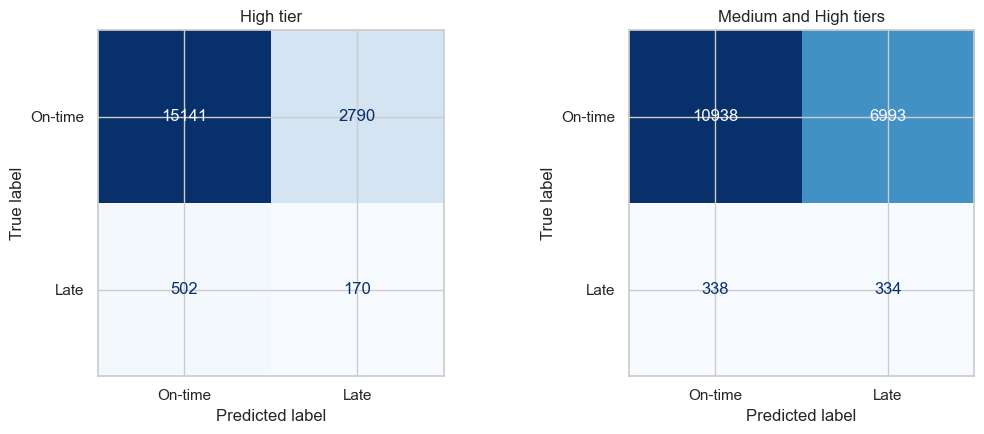

,operating point,cut-off,orders flagged %,precision,recall,F1
0,High tier,0.148,15.9,0.057,0.253,0.094
1,Medium and High tiers,0.079,39.4,0.046,0.497,0.084


Classification report, High tier:
              precision    recall  f1-score   support

     On-time      0.968     0.844     0.902     17931
        Late      0.057     0.253     0.094       672

    accuracy                          0.823     18603
   macro avg      0.513     0.549     0.498     18603
weighted avg      0.935     0.823     0.873     18603

Mean predicted probability: training 7.12% (actual 7.12%)   test 8.87% (actual 3.61%)
Brier score on test: model 0.0406   constant training late rate 0.0360  (lower is better)


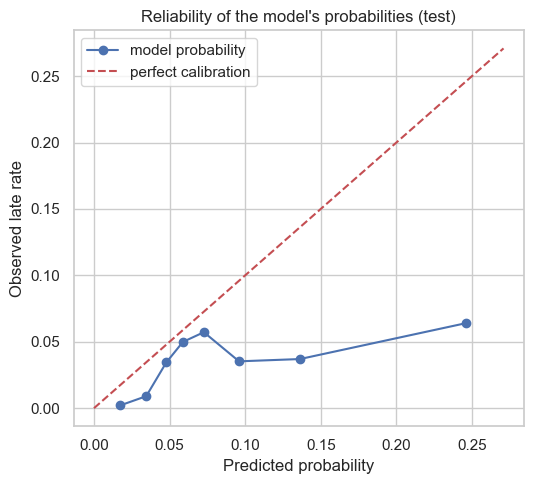

model_metadata.json updated with the final tier cut-offs


In [25]:
cut_med2 = float(np.quantile(train_scores, MEDIUM_Q))
cut_high2 = float(np.quantile(train_scores, HIGH_Q))


def to_tier_v2(scores):
    scores = np.asarray(scores)
    return np.where(scores >= cut_high2, "High", np.where(scores >= cut_med2, "Medium", "Low"))


def tier_table(y, scores):
    t = pd.DataFrame({"tier": to_tier_v2(scores), "y": np.asarray(y)})
    out = (t.groupby("tier").agg(orders=("y", "size"), late_orders=("y", "sum"), late_rate=("y", "mean"))
           .reindex(["High", "Medium", "Low"]))
    out["share_of_orders_pct"] = (out["orders"] / out["orders"].sum() * 100).round(1)
    out["late_rate_pct"] = (out["late_rate"] * 100).round(2)
    out["share_of_late_orders_pct"] = (out["late_orders"] / out["late_orders"].sum() * 100).round(1)
    return out[["orders", "share_of_orders_pct", "late_orders", "late_rate_pct", "share_of_late_orders_pct"]]


print(f"Medium cut-off: {cut_med2:.4f}    High cut-off: {cut_high2:.4f}  (percentiles of the deployed model's training scores)")
tt_train = tier_table(y_train, train_scores)
tt_test2 = tier_table(y_test, proba)
print("\nTraining set (in-sample):")
display(tt_train)
print("Test set:")
display(tt_test2)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
op2 = []
for ax, (label, cut) in zip(axes, [("High tier", cut_high2), ("Medium and High tiers", cut_med2)]):
    pred = (proba >= cut).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["On-time", "Late"],
                                            ax=ax, colorbar=False, values_format="d", cmap="Blues")
    ax.set_title(label)
    op2.append({"operating point": label, "cut-off": round(cut, 4),
                "orders flagged %": round(pred.mean() * 100, 1),
                "precision": precision_score(y_test, pred, zero_division=0),
                "recall": recall_score(y_test, pred, zero_division=0),
                "F1": f1_score(y_test, pred, zero_division=0)})
finish(fig, "28b_confusion_matrices_tiers.png")
op2 = pd.DataFrame(op2)
display(op2.round(3))
print("Classification report, High tier:")
print(classification_report(y_test, (proba >= cut_high2).astype(int),
                            target_names=["On-time", "Late"], digits=3, zero_division=0))

const = np.full(len(y_test), y_train.mean())
print(f"Mean predicted probability: training {train_scores.mean() * 100:.2f}% (actual {y_train.mean() * 100:.2f}%)   "
      f"test {proba.mean() * 100:.2f}% (actual {prev * 100:.2f}%)")
print(f"Brier score on test: model {brier_score_loss(y_test, proba):.4f}   "
      f"constant training late rate {brier_score_loss(y_test, const):.4f}  (lower is better)")
frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins=8, strategy="quantile")
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(mean_pred, frac_pos, "o-", color=BLUE, label="model probability")
lim = max(mean_pred.max(), frac_pos.max()) * 1.1
ax.plot([0, lim], [0, lim], "r--", label="perfect calibration")
ax.set_xlabel("Predicted probability"); ax.set_ylabel("Observed late rate")
ax.set_title("Reliability of the model's probabilities (test)"); ax.legend()
finish(fig, "29b_probability_reliability.png")

metrics["operating_points_v2"] = op2.round(4).to_dict(orient="records")
metrics["tiers_train_v2"] = tt_train.reset_index().to_dict(orient="records")
metrics["tiers_test_v2"] = tt_test2.reset_index().to_dict(orient="records")
metrics["probability_check"] = {
    "mean_predicted_train_pct": round(float(train_scores.mean() * 100), 2),
    "mean_predicted_test_pct": round(float(proba.mean() * 100), 2),
    "actual_train_pct": round(float(y_train.mean() * 100), 2),
    "actual_test_pct": round(float(prev * 100), 2),
    "brier_model": round(float(brier_score_loss(y_test, proba)), 4),
    "brier_constant": round(float(brier_score_loss(y_test, const)), 4),
}

# Update the saved metadata with the final tier definition used by the app
meta["risk_tiers"] = {
    "medium_cutoff": cut_med2, "high_cutoff": cut_high2,
    "definition": "70th and 90th percentile of the deployed model's scores on the training set",
    "train_late_rate_pct": {t: float(tt_train.loc[t, "late_rate_pct"]) for t in tt_train.index},
    "test_late_rate_pct": {t: float(tt_test2.loc[t, "late_rate_pct"]) for t in tt_test2.index},
}
(MODELS_DIR / "model_metadata.json").write_text(json.dumps(meta, indent=2, default=py), encoding="utf-8")
print("model_metadata.json updated with the final tier cut-offs")

#### Result of the diagnosis

- **Most of the failure was a mismatch, not drift.** The first-version High cut-off (0.0678) flags 10.0% of validation orders by construction, but **36.4% of the deployed model's own training orders**. Of the 37 extra percentage points flagged on the test set (47.2% against 10.0%), about 26 come from this mismatch (the cut-offs were learned from models fitted on earlier windows with lower late rates) and about 11 from the test period itself.
- **The test period looks riskier to the model than it was.** Test scores run higher than training scores (mean 0.089 against 0.071, 90th percentile 0.188 against 0.148) while the real late rate is half (3.6% against 7.1%). With the redefined cut-offs the High tier therefore covers 15.9% of test orders instead of 10%, and the Medium and High tiers together 39.4% instead of 30%.
- **The redefined tiers order correctly but separate weakly.** On the test set the late rate is 5.74% (High), 3.76% (Medium) and 3.00% (Low). On the training data itself it is 21.3%, 10.7% and 4.1%, so the training figures are optimistic. The tiers are a ranking aid, not a reliable estimate of an individual order's chance.
- **The probabilities are right for the training period only.** They match in-sample (7.12% predicted, 7.12% actual) but run about 2.5 times too high on the test set (8.87% against 3.61%), and the Brier score (0.0406) is slightly worse than predicting the constant training late rate (0.0360). The model's output should therefore be read as *relative risk*.

### 7.4 Feature importance

Permutation importance on the test set: each original feature is shuffled in turn and the drop in PR-AUC is measured (the whole pipeline is used, so one-hot columns are grouped back into their original feature). A value near zero means the model barely uses that feature.

,feature,importance,std
0,estimated_delivery_days,0.0311,0.0007
1,customer_state,0.0071,0.0011
2,seller_state,0.0054,0.0014
3,n_items,0.0046,0.0013
4,distance_km,0.0027,0.0008
5,shipping_limit_days,0.0021,0.0007
6,total_price,0.0013,0.0009
7,n_sellers,0.0008,0.0006
8,total_freight,0.0006,0.0025
9,payment_type,0.0005,0.0002


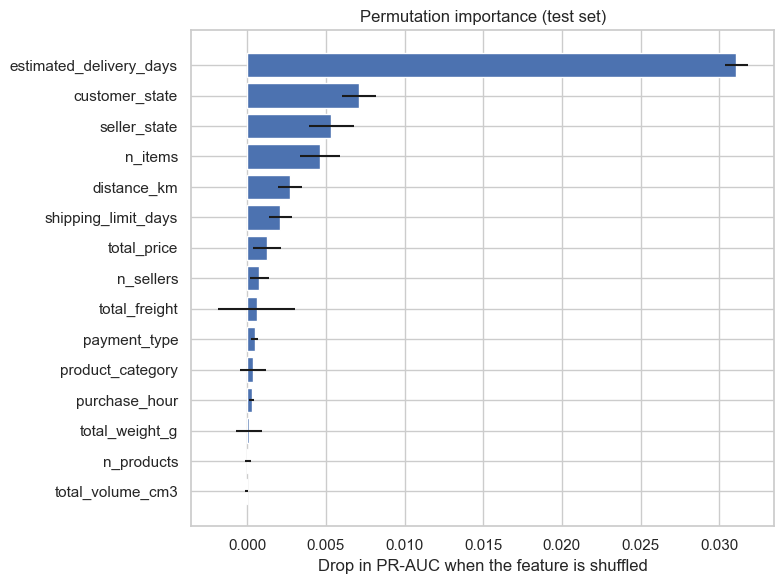

In [26]:
perm = permutation_importance(final, X_test, y_test, scoring="average_precision",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
imp = (pd.DataFrame({"feature": X_test.columns, "importance": perm.importances_mean,
                     "std": perm.importances_std})
       .sort_values("importance", ascending=False).reset_index(drop=True))
display(imp.round(4))
top = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["feature"], top["importance"], xerr=top["std"], color=BLUE)
ax.set_xlabel("Drop in PR-AUC when the feature is shuffled")
ax.set_title("Permutation importance (test set)")
finish(fig, "30_feature_importance.png")

### 7.5 Error analysis

At the **High-risk** cut-off every test order falls into one of four outcomes: true positive (flagged and late), false positive (flagged, on time), false negative (late but missed) and true negative. We look at who is missed, who is wrongly flagged and where the model works worst.

In [27]:
res_df = test[["order_id", "customer_state", "seller_state", "product_category", "distance_km",
               "estimated_delivery_days", "total_freight", "order_purchase_timestamp", TARGET]].copy()
res_df["score"] = proba
res_df["flag"] = (proba >= cut_high2).astype(int)
res_df["tp"] = ((res_df["flag"] == 1) & (res_df[TARGET] == 1)).astype(int)
res_df["outcome"] = np.select(
    [(res_df["flag"] == 1) & (res_df[TARGET] == 1),
     (res_df["flag"] == 1) & (res_df[TARGET] == 0),
     (res_df["flag"] == 0) & (res_df[TARGET] == 1)],
    ["True positive", "False positive", "False negative"], "True negative")
display(res_df["outcome"].value_counts().to_frame("orders"))

print("Average feature values by outcome:")
display(res_df.groupby("outcome")[["distance_km", "estimated_delivery_days", "total_freight", "score"]]
        .mean().round(2))


def group_perf(col, min_late=15, top=12):
    g = res_df.groupby(col).agg(orders=(TARGET, "size"), late=(TARGET, "sum"),
                                flagged=("flag", "sum"), caught=("tp", "sum"))
    g = g[g["late"] >= min_late].copy()
    g["late_rate_pct"] = (g["late"] / g["orders"] * 100).round(2)
    g["recall"] = (g["caught"] / g["late"]).round(3)
    g["precision"] = (g["caught"] / g["flagged"].replace(0, np.nan)).round(3)
    return g.sort_values("late", ascending=False).head(top)


print("\nPerformance by customer state (states with >= 15 late test orders):")
display(group_perf("customer_state"))
print("Performance by seller state:")
display(group_perf("seller_state", min_late=10))
res_df["month"] = res_df["order_purchase_timestamp"].dt.strftime("%Y-%m")
print("Performance by purchase month (test period):")
display(group_perf("month", min_late=1))

res_df["distance_band"] = pd.cut(res_df["distance_km"], [-1, 100, 300, 600, 1000, 10000],
                                 labels=["<100 km", "100-300", "300-600", "600-1000", ">1000 km"])
print("Performance by distance band:")
display(group_perf("distance_band", min_late=1))

print("Most confident false alarms (flagged High, arrived on time):")
display(res_df[res_df["outcome"] == "False positive"].sort_values("score", ascending=False)
        [["customer_state", "seller_state", "product_category", "distance_km",
          "estimated_delivery_days", "score"]].head(8).round(3))

,orders
outcome,
True negative,15141
False positive,2790
False negative,502
True positive,170


Average feature values by outcome:


,distance_km,estimated_delivery_days,total_freight,score
outcome,,,,
False negative,243.16,11.75,17.17,0.07
False positive,1094.86,20.17,37.70,0.23
True negative,475.78,22.04,22.61,0.06
True positive,1266.31,17.61,37.88,0.26



Performance by customer state (states with >= 15 late test orders):


,orders,late,flagged,caught,late_rate_pct,recall,precision
customer_state,,,,,,,
SP,8611,405,185,25,4.70,0.062,0.135
RJ,2126,68,820,41,3.20,0.603,0.050
BA,602,27,313,17,4.49,0.630,0.054
MG,2058,21,146,4,1.02,0.190,0.027
RS,905,18,181,7,1.99,0.389,0.039
PR,947,16,63,2,1.69,0.125,0.032


Performance by seller state:


... (3 outputs left out)

Performance by distance band:


,orders,late,flagged,caught,late_rate_pct,recall,precision
distance_band,,,,,,,
<100 km,4144,288,35,7,6.95,0.024,0.200
300-600,5773,109,884,35,1.89,0.321,0.040
>1000 km,2826,107,1244,83,3.79,0.776,0.067
100-300,2608,88,74,6,3.37,0.068,0.081
600-1000,3173,73,715,37,2.30,0.507,0.052


Most confident false alarms (flagged High, arrived on time):


,customer_state,seller_state,product_category,distance_km,estimated_delivery_days,score
16796,RJ,SP,bed_bath_table,596.083,14,0.624
15980,RJ,SP,baby,631.741,10,0.612
14287,RJ,SP,bed_bath_table,595.675,10,0.594
17298,RJ,MA,health_beauty,2268.670,12,0.574
9985,SE,SP,auto,1732.252,18,0.542
14443,RS,SP,bed_bath_table,843.333,13,0.527
12323,RJ,RS,sports_leisure,1121.908,9,0.521
17735,RJ,MA,health_beauty,2271.720,13,0.518


### 7.6 Conclusions for the test-set evaluation

1. **The ranking signal is real but modest.** PR-AUC is 0.065 against 0.036 for random guessing (1.80 times better) and ROC-AUC is 0.634. The cross-validated ROC-AUC of the same configuration was 0.666, so ranking quality held up reasonably well on later data. With only 672 late orders in the test set, these numbers carry some noise.
2. **Acting on a small share of orders helps a little.** Flagging the riskiest 5% of test orders gives a precision of 8.2% (lift 2.3). The riskiest 10% contain 19.0% of all late orders, the riskiest 20% contain 29.3% and the riskiest 30% contain 39.4%. The cost is 11 to 20 false alarms for every late order caught, against 3.3 to 5.8 in validation, mostly because the late rate fell from 7 to 9% to 3.6%. The final High tier (15.9% of test orders) has a precision of 5.7% and a recall of 25.3%.
3. **The model mostly ranks by the promised delivery window.** `estimated_delivery_days` dominates the permutation importance (a PR-AUC drop of 0.031, against 0.007 for `customer_state`, 0.005 for `seller_state` and `n_items`, and 0.003 for `distance_km`). `same_state` has a *negative* importance (-0.008): shuffling it slightly improved test PR-AUC, so the pattern it encoded no longer held.
4. **Patterns learned in 2016 to early 2018 only partly held in June to August 2018.** In the test period the closest orders (under 100 km) had the *highest* late rate (6.95%, against 1.9% to 3.8% for the other distance bands), whereas in training the closest decile was the safest (4.2%). The late rate also rose within the test period: 1.16% for June purchases, 3.38% for July and 6.19% for August. The data contains nothing that explains this (no carrier, weather or capacity information), so it is reported as drift, not explained.
5. **The first-version cut-offs failed mainly because of a mismatch, and the probabilities are only valid for the training period** (section 7.3). After redefining the tiers, High, Medium and Low have late rates of 5.7%, 3.8% and 3.0% on the test set. The probabilities average 8.9% against a real 3.6%, so they should be read as relative risk.
6. **The model's largest blind spot is local delivery.** Orders under 100 km are 22% of the test orders but 43% of the late ones (288 of 672), and the High tier flagged only 35 of those 4,144 orders (7 of the late ones). Customers in SP account for 60% of the late orders (405 of 672) but only 6% of them are caught. In contrast, orders over 1,000 km have a recall of 78%, RJ 60% and BA 63%. The model has mostly learned "far means risky", which missed the local delays. Purchases from August account for 58% of all late test orders (393 of 672), and only 19% of them were caught.
7. **A very-low-risk group may exist, but this is a hypothesis.** Under the first-version cut-off (0.0419, fixed on validation data), 25% of test orders scored below it and only 0.58% of them were late (27 of 4,694). This was singled out after seeing the test results, and the final Low tier (61% of orders, 3.0% late) does not show it, so it needs confirming on newer data before anyone relies on it.

## 8. Business insights

The model is used as a **ranking tool**: it sorts orders by delivery risk so a limited operations budget is spent where it matters most. The statements below about sellers, states and categories are checked on *later* data, not only on the period that produced them.

In [28]:
# Do the sellers, states and categories that looked risky in training stay risky in the test period?
s_tr = train.groupby("seller_id")[TARGET].agg(orders_train="size", late_train="mean")
s_te = test.groupby("seller_id")[TARGET].agg(orders_test="size", late_test="mean")
joined = s_tr[s_tr["orders_train"] >= 30].join(s_te[s_te["orders_test"] >= 10], how="inner")
print(f"Sellers with >= 30 training orders and >= 10 test orders: {len(joined)}")
print(f"Spearman correlation of seller late rate, train vs test: "
      f"{joined['late_train'].corr(joined['late_test'], method='spearman'):.3f}")

cut_hi = joined["late_train"].quantile(0.90)
risky = joined[joined["late_train"] >= cut_hi]
rest = joined[joined["late_train"] < cut_hi]
pooled = lambda d: (d["late_test"] * d["orders_test"]).sum() / d["orders_test"].sum() * 100
print(f"Highest-risk 10% of sellers in training (late rate >= {cut_hi * 100:.1f}%): "
      f"test late rate {pooled(risky):.2f}%  (other sellers: {pooled(rest):.2f}%)")

worst_sellers = (s_tr[s_tr["orders_train"] >= 30].sort_values("late_train", ascending=False).head(10)
                 .join(s_te, how="left"))
worst_sellers.index = worst_sellers.index.str[:8] + "..."
worst_sellers[["late_train", "late_test"]] = (worst_sellers[["late_train", "late_test"]] * 100).round(1)
print("\nTen highest-risk sellers in training and what happened to them in the test period:")
display(worst_sellers)

for col, min_train in [("customer_state", 200), ("product_category", 300)]:
    a = train.groupby(col)[TARGET].agg(orders_train="size", late_train_pct="mean")
    b = test.groupby(col)[TARGET].agg(orders_test="size", late_test_pct="mean")
    t = a[a["orders_train"] >= min_train].join(b, how="inner")
    t[["late_train_pct", "late_test_pct"]] = (t[["late_train_pct", "late_test_pct"]] * 100).round(2)
    print(f"\n{col}: highest training late rates and their rate in the test period")
    display(t.sort_values("late_train_pct", ascending=False).head(8))

Sellers with >= 30 training orders and >= 10 test orders: 231
Spearman correlation of seller late rate, train vs test: 0.045
Highest-risk 10% of sellers in training (late rate >= 13.2%): test late rate 5.42%  (other sellers: 3.37%)

Ten highest-risk sellers in training and what happened to them in the test period:


,orders_train,late_train,orders_test,late_test
seller_id,,,,
54965bbe...,45,48.9,20.0,0.0
ad781527...,34,35.3,NaN,NaN
ede0c036...,42,33.3,NaN,NaN
835f0f78...,41,26.8,NaN,NaN
2a1348e9...,45,26.7,2.0,0.0
88460e8e...,156,24.4,79.0,5.1
602044f2...,33,24.2,11.0,0.0
ef990a83...,33,24.2,8.0,12.5
2eb70248...,61,21.3,69.0,1.4



customer_state: highest training late rates and their rate in the test period


,orders_train,late_train_pct,orders_test,late_test_pct
customer_state,,,,
AL,321,23.99,62,6.45
MA,589,18.51,109,12.84
SE,253,17.00,74,2.70
CE,1025,15.61,211,0.47
RJ,9915,13.74,2126,3.20
PI,379,12.66,81,13.58
BA,2504,12.46,602,4.49
PA,745,11.41,154,1.95



product_category: highest training late rates and their rate in the test period


,orders_train,late_train_pct,orders_test,late_test_pct
product_category,,,,
home_confort,309,10.36,54,3.70
construction_tools_construction,372,9.14,327,5.20
baby,2079,9.04,604,4.80
electronics,2008,8.62,426,2.11
bed_bath_table,7223,8.35,1689,2.55
musical_instruments,474,8.23,117,4.27
office_furniture,1048,8.02,145,6.90
auto,2761,7.82,930,3.66


### 8.1 What the later data says about sellers, states and categories

- **Individual seller rates did not persist.** Across 231 sellers with at least 30 training and 10 test orders, the rank correlation between training and test late rates is **0.045**, essentially none. At group level there is a weak effect: the highest-risk 10% of sellers in training were late 5.42% of the time in the test period, against 3.37% for the others. Of the ten worst sellers in training, three had no test orders at all; of the seven that did, four had no late order and only one was above 10% (8 orders, 1 late). The "worst sellers" list from the exploratory analysis was mostly noise or short-lived problems.
- **The regional picture is mixed.** Late rates fell almost everywhere in the test period, so the ranking of states is only partly stable: AL 24.0% to 6.5%, CE 15.6% to 0.5%, SE 17.0% to 2.7%, RJ 13.7% to 3.2%, BA 12.5% to 4.5%. MA (18.5% to 12.8%, 109 test orders) and PI (12.7% to 13.6%, 81 test orders) stayed high, but on few orders. The exploratory finding that the north and north-east are worse holds for 2016 to 2018 as a whole, but not as a stable rule.
- **Category rankings are not stable either.** Every high-risk category had a lower late rate in the test period (for example baby 9.0% to 4.8%, bed_bath_table 8.4% to 2.6%), and categories alone carry almost no predictive weight (permutation importance 0.0004).
- **São Paulo dominates the volume.** SP customers placed 46% of the test orders and account for 405 of the 672 late orders (60%), at a late rate of 4.7%.

### 8.2 Recommended actions

1. **Use the model as a prioritisation aid, not as an alarm.** Build a review queue sized to the team's capacity (the top 5% to 10% by risk), and expect roughly 11 to 20 false alarms per late order caught at the current late rate. Measure with a controlled trial whether the intervention (early customer contact, expedited shipping, a seller reminder) really reduces late deliveries, because the model predicts risk but does not show what works.
2. **Do not rely on the Low tier to skip checks yet.** The final Low tier is late 3.0% of the time against 3.6% overall, which is too small a difference to justify skipping anything. A very-low-score group seen in the first version (0.58% late) is a hypothesis to confirm on newer data first (7.6, point 7).
3. **Review the promised delivery windows.** The promise is the strongest signal the model uses, so check route by route whether promises are padded or too tight, especially for the shortest promises.
4. **Monitor drift and retrain regularly.** The late rate moved from about 7% in training to 1% to 6% by month in the test period, and the effect of distance reversed. Track the weekly late rate and the share of orders per risk tier, and retrain when they move away from the values seen in training.
5. **Treat seller lists as watch lists, not penalties.** Individual seller late rates did not persist, so use rolling windows and minimum volumes (at least 30 to 50 orders) before acting on a seller, and avoid blanket regional measures.

### 8.3 Limitations

- **Modest predictive signal.** The model ranks risk better than chance, but precision is low, so it prioritises and does not predict.
- **Time shift.** The late rate, the promised windows and the effect of distance all changed between training and test, and the probabilities are only valid under conditions similar to the training period: they averaged 8.9% on the test set against a real 3.6% (section 7.3). They should be read as relative risk, not as exact chances.
- **Blind spot for local deliveries.** The model catches only 7 of the 288 late orders under 100 km, and few of the late orders from SP customers (section 7.6, point 6).
- **Small test sample.** Only 672 late orders are in the test set, so metrics and tier results carry noise.
- **Missing drivers.** The data has no weather, carrier, strike, holiday, warehouse-capacity or seller-stock information, which probably cause many delays.
- **Selection bias in the labels.** Only delivered orders with a delivery date can be labelled; canceled, lost and still-in-transit orders are excluded.
- **Simplifications.** Multi-seller orders (1.3%) are attributed to the first seller; distances are straight-line distances between zip-code centres.
- **One marketplace, 2016 to 2018.** The model should not be assumed to transfer to another company or period.
- **Seller identity is not a model input.** Seller-level risk is shown for monitoring only.

## 9. Files exported for the Streamlit application

The app loads the saved pipeline instead of retraining. It also needs a few **small** data files for the analytics dashboard, because the raw CSVs are far too large for GitHub and are not available on the server. They are created here.

In [29]:
APP_DATA = ROOT / "app" / "data"
APP_DATA.mkdir(parents=True, exist_ok=True)

# 1. Test-set predictions (never seen during training) for the risk-distribution charts
dash = test[["order_purchase_timestamp", "customer_state", "seller_state", "product_category",
             "distance_km", "estimated_delivery_days", "total_price", "total_freight", TARGET]].copy()
dash["score"] = proba
dash["risk_tier"] = to_tier_v2(proba)
dash.to_csv(APP_DATA / "dashboard_test_predictions.csv", index=False)

# 2. Delivery statistics from the whole labelled table (descriptive, no model involved)
by_state = df.groupby("customer_state").agg(
    orders=(TARGET, "size"), late_rate_pct=(TARGET, "mean"),
    avg_actual_days=("actual_delivery_days", "mean"),
    avg_promised_days=("estimated_delivery_days", "mean")).reset_index()
by_state["late_rate_pct"] *= 100
by_cat = df.groupby("product_category").agg(
    orders=(TARGET, "size"), late_rate_pct=(TARGET, "mean"),
    avg_actual_days=("actual_delivery_days", "mean")).reset_index()
by_cat["late_rate_pct"] *= 100
by_month = df.groupby("purchase_year_month").agg(
    orders=(TARGET, "size"), late_rate_pct=(TARGET, "mean")).reset_index()
by_month["late_rate_pct"] *= 100
by_seller = df.groupby("seller_id").agg(
    orders=(TARGET, "size"), late_orders=(TARGET, "sum"), late_rate_pct=(TARGET, "mean"),
    seller_state=("seller_state", "first"), avg_distance_km=("distance_km", "mean")).reset_index()
by_seller["late_rate_pct"] *= 100
by_seller = by_seller[by_seller["orders"] >= 30]
for name, t in [("stats_by_customer_state", by_state), ("stats_by_category", by_cat),
                ("stats_by_month", by_month), ("stats_by_seller", by_seller)]:
    t.round(3).to_csv(APP_DATA / f"{name}.csv", index=False)

# 3. Importance and metrics for the Home / About pages
imp.round(5).to_csv(APP_DATA / "feature_importance.csv", index=False)
metrics["cv_pr_auc_mean"] = float(chosen_row["pr_auc"])
metrics["cv_pr_auc_std"] = float(chosen_row["pr_auc_std"])
metrics["model_comparison_cv"] = (cv5.groupby("model")[["pr_auc", "roc_auc", "recall_top10"]]
                                  .mean().round(4).reset_index().to_dict(orient="records"))
metrics["tier_cutoffs"] = {"medium": cut_med2, "high": cut_high2}
(APP_DATA / "metrics.json").write_text(json.dumps(metrics, indent=2, default=py), encoding="utf-8")

# 4. Values for the single-prediction form (allowed choices and typical defaults from TRAINING data)
form_defaults = {
    "categorical": {c: sorted(X_train[c].dropna().unique().tolist())
                    for c in ["customer_state", "seller_state", "product_category", "payment_type"]},
    "numeric_median": {c: float(X_train[c].median()) for c in NUMERIC_MODEL},
    "numeric_p01": {c: float(X_train[c].quantile(0.01)) for c in NUMERIC_MODEL},
    "numeric_p99": {c: float(X_train[c].quantile(0.99)) for c in NUMERIC_MODEL},
}
(APP_DATA / "form_defaults.json").write_text(json.dumps(form_defaults, indent=2), encoding="utf-8")

print("Exported files:")
for p in sorted(APP_DATA.glob("*")):
    print(f"  {p.relative_to(ROOT)}  ({p.stat().st_size / 1024:.0f} KB)")
for p in [MODEL_PATH, MODELS_DIR / "model_metadata.json"]:
    print(f"  {p.relative_to(ROOT)}  ({p.stat().st_size / 1024:.0f} KB)")

Exported files:
  app\data\dashboard_test_predictions.csv  (1825 KB)
  app\data\feature_importance.csv  (1 KB)
  app\data\form_defaults.json  (4 KB)
  app\data\metrics.json  (4 KB)
  app\data\stats_by_category.csv  (3 KB)
  app\data\stats_by_customer_state.csv  (1 KB)
  app\data\stats_by_month.csv  (0 KB)
  app\data\stats_by_seller.csv  (34 KB)
  models\late_delivery_pipeline.joblib  (6 KB)
  models\model_metadata.json  (2 KB)


### Final checklist

- The notebook ran from top to bottom with **Restart & Run All** and no errors.
- All leakage checks in section 4 show `[OK]`.
- The test set was used only in sections 7 to 9.
- `models/late_delivery_pipeline.joblib` and the files in `app/data/` exist and are small enough for GitHub (each file far below 100 MB).

Next: build the Streamlit app, push to GitHub and deploy it on Streamlit Community Cloud.